In [1]:
import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


BASE_DIR = Path.cwd()


HUC8_CODES = [
    "03130001",  # Upper Chattahoochee
    "03130002",  # Middle Chattahoochee-Lake Harding
    "03130003",  # Middle Chattahoochee-Walter F. George
    "03130004"   # Lower Chattahoochee
]


WBD_URL = (
    "https://hydro.nationalmap.gov/"
    "arcgis/rest/services/wbd/FeatureServer/4/query"
)


where_clause = (
    "HUC8 IN ("
    +
    ",".join(
        f"'{code}'"
        for code in HUC8_CODES
    )
    +
    ")"
)


params = {
    "where": where_clause,
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}


response = requests.get(
    WBD_URL,
    params=params,
    timeout=60
)

response.raise_for_status()


geojson = response.json()


huc8 = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)


print(
    "HUC-8 polygons downloaded:",
    len(huc8)
)

print()

print(
    huc8[
        [
            "huc8",
            "name",
            "areasqkm",
            "states"
        ]
    ]
)

HUC-8 polygons downloaded: 4

       huc8                               name  areasqkm    states
0  03130002  Middle Chattahoochee-Lake Harding   7875.21     AL,GA
1  03130003      Middle Chattahoochee-Walter F   7347.50     AL,GA
2  03130004                Lower Chattahoochee   3222.47  AL,FL,GA
3  03130001                Upper Chattahoochee   4106.87        GA


In [2]:
huc8 = (
    huc8
    .sort_values("huc8")
    .reset_index(drop=True)
)


chatt_basin = (
    huc8[
        ["geometry"]
    ]
    .dissolve()
    .reset_index(drop=True)
)


chatt_basin["name"] = (
    "Chattahoochee River Basin"
)


min_lon, min_lat, max_lon, max_lat = (
    chatt_basin.total_bounds
)


print(
    "Chattahoochee River Basin"
)

print(
    "=" * 50
)

print(
    f"Minimum longitude: {min_lon:.6f}"
)

print(
    f"Maximum longitude: {max_lon:.6f}"
)

print(
    f"Minimum latitude:  {min_lat:.6f}"
)

print(
    f"Maximum latitude:  {max_lat:.6f}"
)

print()

print(
    "Bounding box:"
)

print(
    [
        round(min_lon, 6),
        round(min_lat, 6),
        round(max_lon, 6),
        round(max_lat, 6)
    ]
)

Chattahoochee River Basin
Minimum longitude: -85.586169
Maximum longitude: -83.408504
Minimum latitude:  30.706264
Maximum latitude:  34.827841

Bounding box:
[np.float64(-85.586169), np.float64(30.706264), np.float64(-83.408504), np.float64(34.827841)]


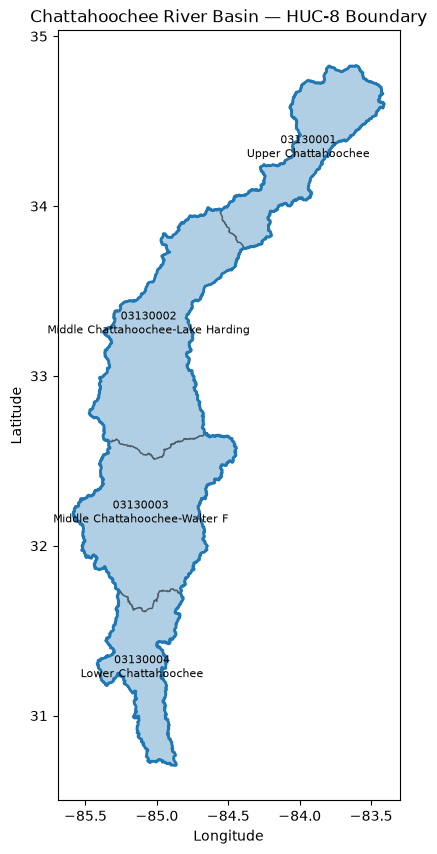


Saved:
chattahoochee_huc8_subbasins.geojson
chattahoochee_basin_boundary.geojson


In [3]:
HUC_FILE = (
    BASE_DIR
    / "chattahoochee_huc8_subbasins.geojson"
)

BASIN_FILE = (
    BASE_DIR
    / "chattahoochee_basin_boundary.geojson"
)


huc8.to_file(
    HUC_FILE,
    driver="GeoJSON"
)


chatt_basin.to_file(
    BASIN_FILE,
    driver="GeoJSON"
)


fig, ax = plt.subplots(
    figsize=(8, 10)
)


huc8.plot(
    ax=ax,
    edgecolor="black",
    alpha=0.35
)


chatt_basin.boundary.plot(
    ax=ax,
    linewidth=2
)


for _, row in huc8.iterrows():

    point = (
        row.geometry
        .representative_point()
    )


    ax.text(
        point.x,
        point.y,
        f"{row['huc8']}\n{row['name']}",
        fontsize=8,
        ha="center"
    )


ax.set_title(
    "Chattahoochee River Basin — HUC-8 Boundary"
)

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

plt.show()


print(
    "\nSaved:"
)

print(
    HUC_FILE.name
)

print(
    BASIN_FILE.name
)

In [6]:
import ee
import json


try:
    ee.Initialize()

except Exception:
    ee.Authenticate()
    ee.Initialize()


basin_geojson = json.loads(
    chatt_basin.to_json()
)["features"][0]["geometry"]


basin_ee = ee.Geometry(
    basin_geojson
)


merit = ee.Image(
    "MERIT/Hydro/v1_0_1"
)


print(
    "MERIT bands:"
)

print(
    merit.bandNames().getInfo()
)


projection_info = (
    merit
    .select("dir")
    .projection()
    .getInfo()
)


print(
    "\nNative MERIT projection:"
)

print(
    projection_info
)


Successfully saved authorization token.
MERIT bands:
['elv', 'dir', 'wth', 'wat', 'upa', 'upg', 'hnd', 'viswth']

Native MERIT projection:
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [0.0008333333333333334, 0, -180.00041666666667, 0, -0.0008333333333333334, 84.99958333333333]}


In [7]:
dir_image = (
    merit
    .select("dir")
    .clip(basin_ee)
)


float_image = (
    merit
    .select([
        "upa",
        "elv",
        "wth",
        "hnd"
    ])
    .toFloat()
    .clip(basin_ee)
)


native_projection = (
    merit
    .select("dir")
    .projection()
    .getInfo()
)


native_crs = (
    native_projection[
        "crs"
    ]
)


native_transform = (
    native_projection[
        "transform"
    ]
)


print(
    "CRS:",
    native_crs
)

print(
    "Transform:",
    native_transform
)


dir_task = ee.batch.Export.image.toDrive(

    image=dir_image,

    description=
        "merit_chatt_dir_native",

    fileNamePrefix=
        "merit_chatt_dir_native",

    region=
        basin_ee.bounds(),

    crs=
        native_crs,

    crsTransform=
        native_transform,

    maxPixels=
        1e10,

    fileFormat=
        "GeoTIFF"
)


float_task = ee.batch.Export.image.toDrive(

    image=float_image,

    description=
        "merit_chatt_float_native",

    fileNamePrefix=
        "merit_chatt_float_native",

    region=
        basin_ee.bounds(),

    crs=
        native_crs,

    crsTransform=
        native_transform,

    maxPixels=
        1e10,

    fileFormat=
        "GeoTIFF"
)


dir_task.start()
float_task.start()


print(
    "Started:",
    dir_task.status()
)

print(
    "Started:",
    float_task.status()
)

CRS: EPSG:4326
Transform: [0.0008333333333333334, 0, -180.00041666666667, 0, -0.0008333333333333334, 84.99958333333333]
Started: {'state': 'READY', 'description': 'merit_chatt_dir_native', 'priority': 100, 'creation_timestamp_ms': 1792890047491, 'update_timestamp_ms': 1792890047491, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'XKSVTE6HKUGWEYGXYZE3BURS', 'name': 'projects/651342185213/operations/XKSVTE6HKUGWEYGXYZE3BURS'}
Started: {'state': 'READY', 'description': 'merit_chatt_float_native', 'priority': 100, 'creation_timestamp_ms': 1792890050915, 'update_timestamp_ms': 1792890050915, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'B6IKPA7ZSQHKIKASF66S2MBL', 'name': 'projects/651342185213/operations/B6IKPA7ZSQHKIKASF66S2MBL'}


In [8]:
import rasterio
import numpy as np


DIR_FILE = (
    "merit_chatt_dir_native.tif"
)

FLOAT_FILE = (
    "merit_chatt_float_native.tif"
)


with rasterio.open(
    DIR_FILE
) as src:

    print(
        "DIR"
    )

    print(
        "Shape:",
        (
            src.height,
            src.width
        )
    )

    print(
        "Bands:",
        src.count
    )

    print(
        "CRS:",
        src.crs
    )

    print(
        "Transform:",
        src.transform
    )


with rasterio.open(
    FLOAT_FILE
) as src:

    print(
        "\nFLOAT"
    )

    print(
        "Shape:",
        (
            src.height,
            src.width
        )
    )

    print(
        "Bands:",
        src.count
    )

    print(
        "CRS:",
        src.crs
    )

    print(
        "Transform:",
        src.transform
    )


    upa = src.read(
        1
    )

    elv = src.read(
        2
    )

    wth = src.read(
        3
    )

    hnd = src.read(
        4
    )


print(
    "\nUPA max:",
    np.nanmax(
        upa
    )
)

print(
    "Elevation range:",
    np.nanmin(elv),
    "to",
    np.nanmax(elv)
)

print(
    "Width max:",
    np.nanmax(
        wth
    )
)

DIR
Shape: (4946, 2614)
Bands: 1
CRS: GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Transform: | 0.00, 0.00,-85.59|
| 0.00,-0.00, 34.83|
| 0.00, 0.00, 1.00|

FLOAT
Shape: (4946, 2614)
Bands: 4
CRS: GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Transform: | 0.00, 0.00,-85.59|
| 0.00,-0.00, 34.83|
| 0.00, 0.00, 1.00|

UPA max: 44535.836
Elevation range: 21.5 to 1341.7001
Width max: 2864.8687


In [9]:
from rasterio.features import geometry_mask
from shapely.geometry import mapping


with rasterio.open(
    FLOAT_FILE
) as src:

    raster_transform = (
        src.transform
    )

    raster_shape = (
        src.height,
        src.width
    )


basin_geometry = (
    chatt_basin
    .geometry
    .iloc[0]
)


inside_basin = ~geometry_mask(

    [
        mapping(
            basin_geometry
        )
    ],

    out_shape=
        raster_shape,

    transform=
        raster_transform,

    invert=False
)


print(
    "Raster cells:",
    inside_basin.size
)

print(
    "Cells inside basin:",
    inside_basin.sum()
)

print(
    "Percent inside basin:",
    round(
        100
        * inside_basin.mean(),
        2
    ),
    "%"
)

Raster cells: 12928844
Cells inside basin: 3127288
Percent inside basin: 24.19 %


In [10]:
thresholds = [
    25,
    50,
    100,
    250,
    500,
    1000,
    2500,
    5000,
    10000
]


print(
    "Chattahoochee MERIT river threshold audit"
)

print(
    "=" * 55
)


for threshold in thresholds:

    river_mask = (

        inside_basin

        &

        np.isfinite(
            upa
        )

        &

        (
            upa
            >= threshold
        )
    )


    print(
        f"{threshold:>6,} km² : "
        f"{river_mask.sum():>10,} pixels"
    )

Chattahoochee MERIT river threshold audit
    25 km² :     41,362 pixels
    50 km² :     29,798 pixels
   100 km² :     20,881 pixels
   250 km² :     13,065 pixels
   500 km² :      8,892 pixels
 1,000 km² :      6,976 pixels
 2,500 km² :      6,008 pixels
 5,000 km² :      4,812 pixels
10,000 km² :      3,062 pixels


In [11]:
import networkx as nx
import numpy as np
import rasterio

from rasterio.transform import xy


RIVER_THRESHOLD_KM2 = 100


river_mask = (
    inside_basin
    &
    np.isfinite(upa)
    &
    (upa >= RIVER_THRESHOLD_KM2)
)


print(
    "River threshold:",
    RIVER_THRESHOLD_KM2,
    "km²"
)

print(
    "River pixels:",
    river_mask.sum()
)

River threshold: 100 km²
River pixels: 20881


In [12]:
with rasterio.open(
    DIR_FILE
) as src:

    flow_dir = src.read(1)

    transform = src.transform

    height = src.height
    width = src.width


print(
    "Raster shape:",
    flow_dir.shape
)

Raster shape: (4946, 2614)


In [13]:
D8 = {

    1:   (0, 1),    # East
    2:   (1, 1),    # Southeast
    4:   (1, 0),    # South
    8:   (1, -1),   # Southwest

    16:  (0, -1),   # West
    32:  (-1, -1),  # Northwest
    64:  (-1, 0),   # North
    128: (-1, 1)    # Northeast
}

In [14]:
G_chatt_full = nx.DiGraph()


river_rows, river_cols = np.where(
    river_mask
)


for row, col in zip(
    river_rows,
    river_cols
):

    node = (
        int(row) * width
        +
        int(col)
    )


    lon, lat = xy(
        transform,
        row,
        col,
        offset="center"
    )


    G_chatt_full.add_node(

        node,

        row=int(row),
        col=int(col),

        longitude=float(lon),
        latitude=float(lat),

        upstream_area_km2=
            float(
                upa[
                    row,
                    col
                ]
            ),

        elevation_m=
            float(
                elv[
                    row,
                    col
                ]
            ),

        river_width_m=
            float(
                wth[
                    row,
                    col
                ]
            ),

        hand_m=
            float(
                hnd[
                    row,
                    col
                ]
            )
    )


print(
    "Nodes created:",
    G_chatt_full.number_of_nodes()
)

Nodes created: 20881


In [15]:
river_node_lookup = {

    (
        int(row),
        int(col)
    ):
    (
        int(row) * width
        +
        int(col)
    )

    for row, col in zip(
        river_rows,
        river_cols
    )
}


for row, col in zip(
    river_rows,
    river_cols
):

    direction = int(
        flow_dir[
            row,
            col
        ]
    )


    if direction not in D8:
        continue


    dr, dc = D8[
        direction
    ]


    downstream_row = (
        int(row)
        +
        dr
    )


    downstream_col = (
        int(col)
        +
        dc
    )


    downstream_cell = (
        downstream_row,
        downstream_col
    )


    if downstream_cell not in river_node_lookup:
        continue


    u = (
        int(row) * width
        +
        int(col)
    )


    v = river_node_lookup[
        downstream_cell
    ]


    G_chatt_full.add_edge(
        u,
        v
    )

In [16]:
print(
    "Directed:",
    G_chatt_full.is_directed()
)

print(
    "Nodes:",
    G_chatt_full.number_of_nodes()
)

print(
    "Edges:",
    G_chatt_full.number_of_edges()
)

print(
    "Weak components:",
    nx.number_weakly_connected_components(
        G_chatt_full
    )
)

Directed: True
Nodes: 20881
Edges: 20879
Weak components: 2


In [17]:
components = sorted(

    nx.weakly_connected_components(
        G_chatt_full
    ),

    key=len,

    reverse=True
)


component_sizes = [
    len(component)
    for component in components
]


print(
    "Largest component sizes:"
)

print(
    component_sizes[:20]
)

Largest component sizes:
[20871, 10]


In [18]:
largest_nodes = (
    components[0]
)


G_chatt_largest = (
    G_chatt_full
    .subgraph(
        largest_nodes
    )
    .copy()
)


print(
    "Largest component nodes:",
    G_chatt_largest.number_of_nodes()
)

print(
    "Largest component edges:",
    G_chatt_largest.number_of_edges()
)

print(
    "Weak components:",
    nx.number_weakly_connected_components(
        G_chatt_largest
    )
)

Largest component nodes: 20871
Largest component edges: 20870
Weak components: 1


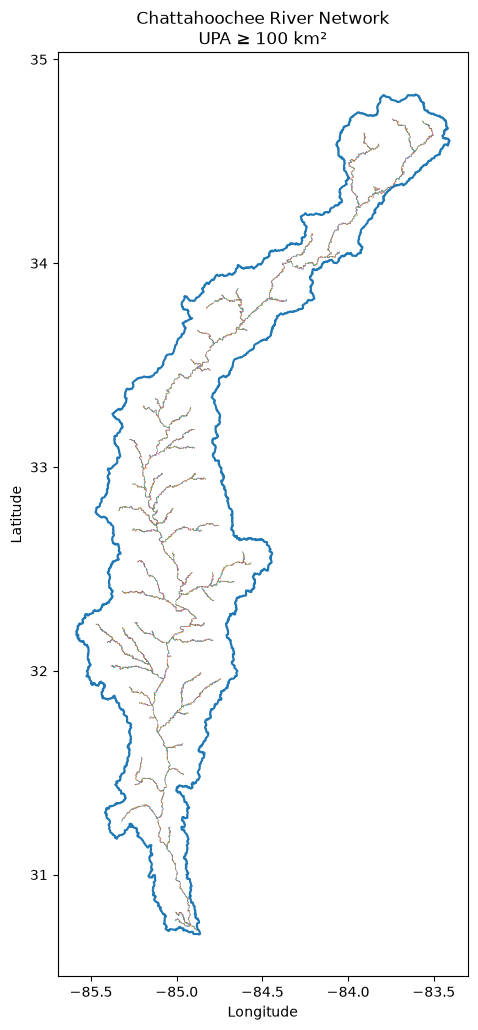

In [19]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(
    figsize=(8, 12)
)


for u, v in G_chatt_largest.edges():

    udata = G_chatt_largest.nodes[u]

    vdata = G_chatt_largest.nodes[v]


    ax.plot(
        [
            udata["longitude"],
            vdata["longitude"]
        ],
        [
            udata["latitude"],
            vdata["latitude"]
        ],
        linewidth=0.4
    )


chatt_basin.boundary.plot(
    ax=ax,
    linewidth=1.5
)


ax.set_title(
    "Chattahoochee River Network\nUPA ≥ 100 km²"
)

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

plt.show()

In [20]:
import pickle


with open(
    "chattahoochee_full_threshold100.pkl",
    "wb"
) as f:

    pickle.dump(
        G_chatt_full,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


with open(
    "chattahoochee_largest_component_threshold100.pkl",
    "wb"
) as f:

    pickle.dump(
        G_chatt_largest,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


print(
    "Graphs saved."
)

Graphs saved.


In [21]:
import requests
import geopandas as gpd
import pandas as pd
import numpy as np


HUC8_CODES = [
    "03130001",
    "03130002",
    "03130003",
    "03130004"
]


MONITORING_URL = (
    "https://api.waterdata.usgs.gov/"
    "ogcapi/v1/collections/"
    "monitoring-locations/items"
)


def get_usgs_locations_for_huc(
    huc8
):

    params = {
        "f": "json",
        "limit": 10000,
        "agency_code": "USGS",
        "hydrologic_unit_code": huc8
    }


    features = []

    url = MONITORING_URL


    while url is not None:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        response.raise_for_status()

        data = response.json()


        features.extend(
            data.get(
                "features",
                []
            )
        )


        next_url = None

        for link in data.get(
            "links",
            []
        ):

            if link.get("rel") == "next":

                next_url = link.get(
                    "href"
                )

                break


        url = next_url

        # next URL already contains its query string
        params = None


    return features


all_features = []


for huc8 in HUC8_CODES:

    print(
        "Downloading HUC:",
        huc8
    )


    features = (
        get_usgs_locations_for_huc(
            huc8
        )
    )


    print(
        "  locations:",
        len(features)
    )


    all_features.extend(
        features
    )


usgs_sites = (
    gpd.GeoDataFrame.from_features(
        all_features,
        crs="EPSG:4326"
    )
)


usgs_sites = (
    usgs_sites
    .drop_duplicates(
        subset="id"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nUnique USGS locations:",
    len(usgs_sites)
)


print(
    "\nSite types:"
)


display(
    usgs_sites[
        [
            "site_type_code",
            "site_type"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "site_type_code"
    )
)

  locations: 1262
  locations: 1411
  locations: 629
  locations: 446

Unique USGS locations: 3748

Site types:


,site_type_code,site_type
1100,AG,Aggregate groundwater use
1135,AS,Aggregate surface-water-use
458,AT,Atmosphere
215,FA-DV,Diversion
1103,FA-GC,Golf course
1108,FA-HP,Hydroelectric plant
402,FA-OF,Outfall
425,FA-PV,Pavement
286,FA-QC,Laboratory or sample-preparation area
2538,FA-TEP,Thermoelectric plant


In [22]:
flowing_sites = (
    usgs_sites[
        usgs_sites[
            "site_type_code"
        ] == "ST"
    ]
    .copy()
)


flowing_sites = (
    flowing_sites[
        flowing_sites.geometry.intersects(
            chatt_basin.geometry.iloc[0]
        )
    ]
    .copy()
)


print(
    "All USGS monitoring locations:",
    len(usgs_sites)
)

print(
    "Stream monitoring locations:",
    len(flowing_sites)
)

All USGS monitoring locations: 3748
Stream monitoring locations: 846


In [23]:
print(
    "Unique stream stations:",
    flowing_sites[
        "monitoring_location_number"
    ].nunique()
)


display(
    flowing_sites[
        [
            "monitoring_location_number",
            "monitoring_location_name",
            "site_type_code",
            "hydrologic_unit_code"
        ]
    ].head(20)
)

Unique stream stations: 846


,monitoring_location_number,monitoring_location_name,site_type_code,hydrologic_unit_code
2,02330440,"CHATTAHOOCHEE RIVER ABOVE ROBERTSTOWN, GA",ST,03130001
3,02330448,"CHATTAHOOCHEE RIVER COUNTY RD AT HELEN, GA",ST,03130001
4,02330450,"CHATTAHOOCHEE RIVER AT HELEN, GA",ST,03130001
5,02330453,"CHATTAHOOCHEE R AT GA 17 AND 75, AT NACOOCHEE, GA",ST,03130001
6,02330454,"CHATTAHOOCHEE RIVER AT GA 75, AT NACOOCHEE, GA",ST,03130001
7,02330455,"CHATTAHOOCHEE RIVER NEAR NACOOCHEE, GA",ST,03130001
8,02330465,"DUKES CREEK NEAR HELEN, GA",ST,03130001
9,02330467,"SHOAL CR AT ALEX STRINGER RD NEAR CLEVELAND, GA",ST,03130001
10,02330470,"DUKES CREEK AT GA 75, NEAR NACOOCHEE, GA",ST,03130001
11,02330472,"DUKES CREEK MOUTH NEAR NACOOCHEE, GA",ST,03130001


In [25]:
river_node_rows = []


for node, data in G_chatt_largest.nodes(
    data=True
):

    river_node_rows.append({

        "node":
            node,

        "longitude":
            data[
                "longitude"
            ],

        "latitude":
            data[
                "latitude"
            ],

        "upstream_area_km2":
            data[
                "upstream_area_km2"
            ]
    })


river_nodes_gdf = gpd.GeoDataFrame(

    river_node_rows,

    geometry=gpd.points_from_xy(

        [
            row["longitude"]
            for row in river_node_rows
        ],

        [
            row["latitude"]
            for row in river_node_rows
        ]
    ),

    crs="EPSG:4326"
)


print(
    "River graph nodes:",
    len(river_nodes_gdf)
)

River graph nodes: 20871


In [26]:
PROJECTED_CRS = (
    "EPSG:5070"
)


river_proj = (
    river_nodes_gdf
    .to_crs(
        PROJECTED_CRS
    )
)


sites_proj = (
    flowing_sites
    .to_crs(
        PROJECTED_CRS
    )
)


snapped_sites = (
    gpd.sjoin_nearest(

        sites_proj,

        river_proj[
            [
                "node",
                "upstream_area_km2",
                "geometry"
            ]
        ],

        how="left",

        distance_col=
            "distance_to_river_m"
    )
)


snapped_sites = (
    snapped_sites
    .to_crs(
        "EPSG:4326"
    )
)


print(
    "Stations snapped:",
    len(snapped_sites)
)


print(
    "\nDistance summary:"
)


display(
    snapped_sites[
        "distance_to_river_m"
    ]
    .describe()
)

Stations snapped: 846

Distance summary:


count      846.000000
mean      3260.874888
std       3496.818467
min          0.000000
25%         62.203785
50%       2109.345096
75%       5683.593489
max      13782.794701
Name: distance_to_river_m, dtype: float64

In [27]:
snap_thresholds = [
    25,
    50,
    100,
    150,
    250,
    500,
    1000,
    2000,
    5000
]


for distance in snap_thresholds:

    count = (
        snapped_sites[
            "distance_to_river_m"
        ]
        .le(
            distance
        )
        .sum()
    )


    print(
        f"{distance:>5} m : "
        f"{count:>4} stations"
    )

   25 m :   56 stations
   50 m :  165 stations
  100 m :  262 stations
  150 m :  277 stations
  250 m :  289 stations
  500 m :  314 stations
 1000 m :  350 stations
 2000 m :  418 stations
 5000 m :  582 stations


In [28]:
display(
    snapped_sites[
        [
            "id",
            "monitoring_location_name",
            "site_type_code",
            "node",
            "distance_to_river_m",
            "upstream_area_km2"
        ]
    ]
    .sort_values(
        "distance_to_river_m"
    )
    .head(30)
)

,id,monitoring_location_name,site_type_code,node,distance_to_river_m,upstream_area_km2
202,USGS-02335405,"CHATTAHOOCHEE R 0.47 MI DS GA140, ALPHARETTA, GA",ST,2680929,0.000000e+00,3131.089355
218,USGS-02335757,"BIG CREEK BELOW HOG WALLOW CREEK AT ROSWELL, GA",ST,2542287,3.492460e-09,266.550995
159,USGS-02334430,"CHATTAHOOCHEE RIVER AT BUFORD DAM, NEAR BUFORD...",ST,2106079,7.656405e+00,2681.990967
203,USGS-02335450,"CHATTAHOOCHEE RIVER ABOVE ROSWELL, GA",ST,2641664,1.311040e+01,3154.214844
1343,USGS-02336850,"SWEETWATER CREEK AT BROWN ROAD, NEAR AUSTELL, GA",ST,3158768,1.323454e+01,258.538452
122,USGS-02333750,"YAHOOLA CREEK AT GA 60, AT DAHLONEGA, GA",ST,1003095,1.339929e+01,491.733002
1473,USGS-02338660,"NEW RIVER AT GA 100, NEAR CORINTH, GA",ST,4993458,1.342891e+01,323.311157
115,USGS-02333460,"TESNATEE CREEK CR 200 NEAR CLEVELAND, GA",ST,768018,1.368823e+01,139.385483
169,USGS-02334550,"CHATT R AT SETTLES BR RD, NEAR SUWANEE, GA",ST,2289021,1.368933e+01,2777.011230
188,USGS-02334910,"SUWANEE CREEK AT MOUTH, NEAR SUWANEE, GA",ST,2490286,1.373706e+01,2850.454346


In [29]:
import requests
import pandas as pd


TIME_SERIES_URL = (
    "https://api.waterdata.usgs.gov/"
    "ogcapi/v0/collections/"
    "time-series-metadata/items"
)


PARAMETERS = {

    "DO concentration":
        "00300",

    "Water temperature":
        "00010",

    "Specific conductance":
        "00095",

    "Turbidity":
        "63680",

    "pH":
        "00400"
}


def get_time_series_metadata(
    huc8,
    parameter_code
):

    params = {

        "f":
            "json",

        "limit":
            10000,

        "hydrologic_unit_code":
            huc8,

        "parameter_code":
            parameter_code
    }


    features = []

    url = TIME_SERIES_URL


    while url is not None:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        response.raise_for_status()


        data = response.json()


        features.extend(
            data.get(
                "features",
                []
            )
        )


        next_url = None


        for link in data.get(
            "links",
            []
        ):

            if link.get(
                "rel"
            ) == "next":

                next_url = link.get(
                    "href"
                )

                break


        url = next_url

        params = None


    return features

In [30]:
metadata_features = []


for variable, pcode in PARAMETERS.items():

    print(
        "\n",
        variable,
        pcode
    )


    for huc8 in HUC8_CODES:

        features = (
            get_time_series_metadata(
                huc8,
                pcode
            )
        )


        print(
            " ",
            huc8,
            "->",
            len(features),
            "time series"
        )


        for feature in features:

            feature[
                "properties"
            ][
                "target_name"
            ] = variable


        metadata_features.extend(
            features
        )


 DO concentration 00300
  03130001 -> 44 time series
  03130002 -> 15 time series
  03130003 -> 0 time series
  03130004 -> 8 time series

 Water temperature 00010
  03130001 -> 162 time series
  03130002 -> 69 time series
  03130003 -> 0 time series
  03130004 -> 8 time series

 Specific conductance 00095
  03130001 -> 83 time series
  03130002 -> 19 time series
  03130003 -> 0 time series
  03130004 -> 8 time series

 Turbidity 63680
  03130001 -> 78 time series
  03130002 -> 15 time series
  03130003 -> 0 time series
  03130004 -> 0 time series

 pH 00400
  03130001 -> 36 time series
  03130002 -> 16 time series
  03130003 -> 0 time series
  03130004 -> 0 time series


In [31]:
metadata_rows = []


for feature in metadata_features:

    props = feature[
        "properties"
    ]


    metadata_rows.append(
        props
    )


ts_metadata = pd.DataFrame(
    metadata_rows
)


print(
    "Total metadata rows:",
    len(ts_metadata)
)


print(
    "Columns:"
)

print(
    ts_metadata.columns.tolist()
)

Total metadata rows: 561
Columns:
['id', 'unit_of_measure', 'parameter_name', 'parameter_code', 'statistic_id', 'hydrologic_unit_code', 'state_name', 'last_modified', 'begin', 'end', 'begin_utc', 'end_utc', 'computation_period_identifier', 'computation_identifier', 'thresholds', 'sublocation_identifier', 'primary', 'monitoring_location_id', 'web_description', 'parameter_description', 'parent_time_series_id', 'data_gap_interval', 'target_name']


In [32]:
continuous_metadata = (
    ts_metadata[
        (
            ts_metadata[
                "computation_identifier"
            ]
            .fillna("")
            == "Instantaneous"
        )
        |
        (
            ts_metadata[
                "computation_period_identifier"
            ]
            .fillna("")
            == "Points"
        )
    ]
    .copy()
)


continuous_metadata = (
    continuous_metadata
    .drop_duplicates(
        subset=[
            "id"
        ]
    )
)


print(
    "Continuous time series:",
    len(
        continuous_metadata
    )
)

Continuous time series: 117


In [33]:
useful_series = (
    continuous_metadata
    .merge(

        snapped_sites[
            [
                "id",
                "monitoring_location_number",
                "monitoring_location_name",
                "node",
                "distance_to_river_m",
                "upstream_area_km2"
            ]
        ],

        left_on=
            "monitoring_location_id",

        right_on=
            "id",

        how=
            "inner",

        suffixes=(
            "_series",
            "_site"
        )
    )
)

In [34]:
parameter_summary = (

    useful_series

    .groupby(
        [
            "target_name",
            "parameter_code"
        ]
    )

    .agg(

        time_series=(
            "id_series",
            "nunique"
        ),

        stations=(
            "monitoring_location_id",
            "nunique"
        )
    )

    .reset_index()
)


display(
    parameter_summary
)

,target_name,parameter_code,time_series,stations
0,DO concentration,00300,16,16
1,Specific conductance,00095,26,26
2,Turbidity,63680,21,21
3,Water temperature,00010,42,42
4,pH,00400,12,12


In [35]:
snap_thresholds = [
    25,
    50,
    100,
    150,
    250,
    500,
    1000
]


coverage_rows = []


for target in PARAMETERS:

    target_sites = (
        useful_series[
            useful_series[
                "target_name"
            ] == target
        ]
        .drop_duplicates(
            subset=[
                "monitoring_location_id"
            ]
        )
    )


    for threshold in snap_thresholds:

        coverage_rows.append({

            "Target":
                target,

            "Threshold_m":
                threshold,

            "Stations":
                (
                    target_sites[
                        "distance_to_river_m"
                    ]
                    <= threshold
                ).sum()
        })


wq_snap_coverage = pd.DataFrame(
    coverage_rows
)


display(
    wq_snap_coverage.pivot(
        index="Target",
        columns="Threshold_m",
        values="Stations"
    )
)

Threshold_m,25,50,100,150,250,500,1000
Target,,,,,,,
DO concentration,1,4,6,6,6,7,9
Specific conductance,1,9,12,12,12,13,16
Turbidity,0,5,7,7,7,8,11
Water temperature,3,14,21,25,25,26,29
pH,0,2,2,2,2,3,5


In [36]:
FINAL_SNAP_DISTANCE_M = 150


selected_series = (
    useful_series[
        useful_series[
            "distance_to_river_m"
        ]
        <= FINAL_SNAP_DISTANCE_M
    ]
    .copy()
)


station_summary = (
    selected_series
    .groupby(
        [
            "monitoring_location_id",
            "monitoring_location_number",
            "monitoring_location_name",
            "node",
            "distance_to_river_m"
        ],
        as_index=False
    )
    .agg(
        variables=(
            "target_name",
            lambda x: sorted(
                set(x)
            )
        )
    )
)


station_summary[
    "n_variables"
] = (
    station_summary[
        "variables"
    ]
    .apply(len)
)


print(
    "Selected continuous-WQ stations:",
    len(station_summary)
)

print(
    "Unique graph nodes:",
    station_summary[
        "node"
    ].nunique()
)


display(
    station_summary
    .sort_values(
        [
            "n_variables",
            "distance_to_river_m"
        ],
        ascending=[
            False,
            True
        ]
    )
)

Selected continuous-WQ stations: 25
Unique graph nodes: 24


,monitoring_location_id,monitoring_location_number,monitoring_location_name,node,distance_to_river_m,variables,n_variables
20,USGS-02336300,02336300,"PEACHTREE CREEK AT ATLANTA, GA",3161740,36.448645,"[DO concentration, Specific conductance, Turbi...",5
21,USGS-02337170,02337170,"CHATTAHOOCHEE RIVER NEAR FAIRBURN, GA",3673765,25.582542,"[DO concentration, Specific conductance, Water...",4
4,USGS-02334500,02334500,"CHATTAHOOCHEE RIVER NEAR BUFORD, GA",2200165,62.305685,"[DO concentration, Specific conductance, Turbi...",4
3,USGS-02334430,02334430,"CHATTAHOOCHEE RIVER AT BUFORD DAM, NEAR BUFORD...",2106079,7.656405,"[DO concentration, Specific conductance, Water...",3
8,USGS-02334885,02334885,"SUWANEE CREEK AT SUWANEE, GA",2495552,25.459951,"[Specific conductance, Turbidity, Water temper...",3
19,USGS-02336000,02336000,"CHATTAHOOCHEE RIVER AT ATLANTA, GA",3038826,25.516549,"[Specific conductance, Turbidity, Water temper...",3
23,USGS-023432415,023432415,CHATTAHOOCHEE R .36 MI DS WFG DAM NR FT GAINES...,10054076,34.021050,"[DO concentration, Specific conductance, Water...",3
9,USGS-02335000,02335000,"CHATTAHOOCHEE RIVER NEAR NORCROSS, GA",2605205,40.156171,"[Specific conductance, Turbidity, Water temper...",3
22,USGS-02337410,02337410,"DOG RIVER AT GA 5, NEAR FAIRPLAY, GA",3681430,44.135355,"[Specific conductance, Turbidity, Water temper...",3
18,USGS-02335880,02335880,"CHATT R AT POWERS FY AND I-285 NR ATLANTA, GA",2905526,59.276430,"[Specific conductance, Turbidity, Water temper...",3


In [37]:
import copy


G_chatt_wq = (
    G_chatt_largest.copy()
)


for node in G_chatt_wq.nodes():

    G_chatt_wq.nodes[node][
        "usgs_stations"
    ] = []

    G_chatt_wq.nodes[node][
        "usgs_station_count"
    ] = 0


for _, row in station_summary.iterrows():

    node = int(
        row["node"]
    )


    station_info = {

        "monitoring_location_id":
            row[
                "monitoring_location_id"
            ],

        "station_number":
            row[
                "monitoring_location_number"
            ],

        "station_name":
            row[
                "monitoring_location_name"
            ],

        "distance_to_river_m":
            float(
                row[
                    "distance_to_river_m"
                ]
            ),

        "variables":
            list(
                row[
                    "variables"
                ]
            ),

        "n_variables":
            int(
                row[
                    "n_variables"
                ]
            )
    }


    G_chatt_wq.nodes[node][
        "usgs_stations"
    ].append(
        station_info
    )


for node in G_chatt_wq.nodes():

    G_chatt_wq.nodes[node][
        "usgs_station_count"
    ] = len(
        G_chatt_wq.nodes[node][
            "usgs_stations"
        ]
    )


wq_nodes = {

    node

    for node, data
    in G_chatt_wq.nodes(
        data=True
    )

    if data[
        "usgs_station_count"
    ] > 0
}


print(
    "WQ stations:",
    len(
        station_summary
    )
)

print(
    "WQ graph nodes:",
    len(
        wq_nodes
    )
)

WQ stations: 25
WQ graph nodes: 24


In [38]:
node_variable_rows = []


for node in sorted(
    wq_nodes
):

    stations = (
        G_chatt_wq.nodes[node][
            "usgs_stations"
        ]
    )


    variables = sorted(
        {
            variable

            for station in stations

            for variable in station[
                "variables"
            ]
        }
    )


    node_variable_rows.append({

        "node":
            node,

        "n_stations":
            len(
                stations
            ),

        "variables":
            variables,

        "n_variables":
            len(
                variables
            )
    })


node_variable_summary = pd.DataFrame(
    node_variable_rows
)


display(
    node_variable_summary
    .sort_values(
        "n_variables",
        ascending=False
    )
)

,node,n_stations,variables,n_variables
19,3161740,1,"[DO concentration, Specific conductance, Turbi...",5
4,2200165,1,"[DO concentration, Specific conductance, Turbi...",4
20,3673765,1,"[DO concentration, Specific conductance, Water...",4
23,11225092,1,"[DO concentration, Specific conductance, Water...",3
22,10054076,1,"[DO concentration, Specific conductance, Water...",3
3,2106079,1,"[DO concentration, Specific conductance, Water...",3
21,3681430,1,"[Specific conductance, Turbidity, Water temper...",3
8,2495552,1,"[Specific conductance, Turbidity, Water temper...",3
9,2605205,1,"[Specific conductance, Turbidity, Water temper...",3
18,3038826,1,"[Specific conductance, Turbidity, Water temper...",3


In [39]:
for variable in PARAMETERS:

    count = sum(

        variable in variables

        for variables
        in node_variable_summary[
            "variables"
        ]

    )


    print(
        f"{variable:<25} : "
        f"{count} graph nodes"
    )

DO concentration          : 6 graph nodes
Water temperature         : 24 graph nodes
Specific conductance      : 12 graph nodes
Turbidity                 : 7 graph nodes
pH                        : 2 graph nodes


In [40]:
for variable in PARAMETERS:

    count = sum(

        variable in variables

        for variables
        in node_variable_summary[
            "variables"
        ]

    )


    print(
        f"{variable:<25} : "
        f"{count} graph nodes"
    )

DO concentration          : 6 graph nodes
Water temperature         : 24 graph nodes
Specific conductance      : 12 graph nodes
Turbidity                 : 7 graph nodes
pH                        : 2 graph nodes


In [42]:
import copy
import numpy as np
import networkx as nx

from math import radians, sin, cos, asin, sqrt


def haversine_m(lon1, lat1, lon2, lat2):

    R = 6371000.0

    lon1 = radians(float(lon1))
    lat1 = radians(float(lat1))
    lon2 = radians(float(lon2))
    lat2 = radians(float(lat2))

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        sin(dlat / 2.0) ** 2
        +
        cos(lat1)
        * cos(lat2)
        * sin(dlon / 2.0) ** 2
    )

    return 2.0 * R * asin(
        sqrt(a)
    )


def get_edge_length_m(
    G,
    u,
    v
):

    data = G.edges[u, v]

    length_m = data.get(
        "length_m",
        None
    )

    if (
        length_m is not None
        and np.isfinite(float(length_m))
        and float(length_m) > 0
    ):

        return float(length_m)


    udata = G.nodes[u]
    vdata = G.nodes[v]

    return haversine_m(
        udata["longitude"],
        udata["latitude"],
        vdata["longitude"],
        vdata["latitude"]
    )


def compress_river_graph(
    G,
    max_steps=None,
    extra_protected_nodes=None
):

    if not G.is_directed():

        raise ValueError(
            "G must be a directed river graph."
        )


    if extra_protected_nodes is None:

        extra_protected_nodes = set()

    else:

        extra_protected_nodes = set(
            extra_protected_nodes
        )


    structural_nodes = set()


    for node in G.nodes():

        indeg = G.in_degree(
            node
        )

        outdeg = G.out_degree(
            node
        )


        if not (
            indeg == 1
            and
            outdeg == 1
        ):

            structural_nodes.add(
                node
            )


    protected_nodes = (
        structural_nodes
        |
        extra_protected_nodes
    )


    H = nx.DiGraph()


    H.graph.update(
        copy.deepcopy(
            G.graph
        )
    )


    H.graph[
        "compression_max_steps"
    ] = max_steps

    H.graph[
        "original_node_count"
    ] = G.number_of_nodes()

    H.graph[
        "original_edge_count"
    ] = G.number_of_edges()

    H.graph[
        "protected_node_count"
    ] = len(
        protected_nodes
    )


    visited_edges = set()


    for start in protected_nodes:

        successors = list(
            G.successors(start)
        )


        for first_next in successors:

            first_edge = (
                start,
                first_next
            )


            if first_edge in visited_edges:
                continue


            path = [
                start,
                first_next
            ]


            visited_edges.add(
                first_edge
            )


            current = first_next

            seen_nodes = {
                start,
                first_next
            }


            while (
                current
                not in protected_nodes
            ):

                next_nodes = list(
                    G.successors(
                        current
                    )
                )


                if len(next_nodes) != 1:
                    break


                nxt = next_nodes[0]


                if nxt in seen_nodes:

                    raise RuntimeError(
                        "Cycle detected in river graph."
                    )


                path.append(
                    nxt
                )


                visited_edges.add(
                    (
                        current,
                        nxt
                    )
                )


                seen_nodes.add(
                    nxt
                )


                current = nxt


            if len(path) < 2:
                continue


            if max_steps is None:

                split_indices = [
                    0,
                    len(path) - 1
                ]


            else:

                if max_steps < 1:

                    raise ValueError(
                        "max_steps must be >= 1 or None."
                    )


                split_indices = list(
                    range(
                        0,
                        len(path) - 1,
                        max_steps
                    )
                )


                if (
                    split_indices[-1]
                    != len(path) - 1
                ):

                    split_indices.append(
                        len(path) - 1
                    )


            for idx in split_indices:

                node = path[idx]


                if node not in H:

                    H.add_node(
                        node,
                        **copy.deepcopy(
                            G.nodes[node]
                        )
                    )


            for left, right in zip(
                split_indices[:-1],
                split_indices[1:]
            ):

                segment = path[
                    left:right + 1
                ]


                u = segment[0]
                v = segment[-1]


                total_length_m = sum(

                    get_edge_length_m(
                        G,
                        a,
                        b
                    )

                    for a, b in zip(
                        segment[:-1],
                        segment[1:]
                    )
                )


                H.add_edge(

                    u,
                    v,

                    length_m=
                        float(
                            total_length_m
                        ),

                    original_edge_count=
                        len(segment) - 1,

                    compressed_node_count=
                        max(
                            len(segment) - 2,
                            0
                        ),

                    original_path=
                        segment.copy()
                )


    missing_protected = (
        protected_nodes
        -
        set(H.nodes())
    )


    for node in missing_protected:

        H.add_node(
            node,
            **copy.deepcopy(
                G.nodes[node]
            )
        )


    return H

In [43]:
G_chatt_10px = compress_river_graph(
    G_chatt_wq,
    max_steps=10,
    extra_protected_nodes=wq_nodes
)


G_chatt_100px = compress_river_graph(
    G_chatt_wq,
    max_steps=100,
    extra_protected_nodes=wq_nodes
)


G_chatt_structural = compress_river_graph(
    G_chatt_wq,
    max_steps=None,
    extra_protected_nodes=wq_nodes
)

In [44]:
graph_comparison = pd.DataFrame({

    "Graph": [
        "Full",
        "10-pixel",
        "100-pixel",
        "Structural"
    ],

    "Nodes": [
        G_chatt_wq.number_of_nodes(),
        G_chatt_10px.number_of_nodes(),
        G_chatt_100px.number_of_nodes(),
        G_chatt_structural.number_of_nodes()
    ],

    "Edges": [
        G_chatt_wq.number_of_edges(),
        G_chatt_10px.number_of_edges(),
        G_chatt_100px.number_of_edges(),
        G_chatt_structural.number_of_edges()
    ]
})


graph_comparison[
    "Compression %"
] = (
    100
    *
    (
        1
        -
        graph_comparison[
            "Nodes"
        ]
        /
        G_chatt_wq.number_of_nodes()
    )
)


display(
    graph_comparison.style.format({
        "Compression %":
            "{:.2f}%"
    })
)

,Graph,Nodes,Edges,Compression %
0,Full,20871,20870,0.00%
1,10-pixel,2163,2162,89.64%
2,100-pixel,295,294,98.59%
3,Structural,160,159,99.23%


In [45]:
for name, G in {

    "Full":
        G_chatt_wq,

    "10-pixel":
        G_chatt_10px,

    "100-pixel":
        G_chatt_100px,

    "Structural":
        G_chatt_structural

}.items():

    missing = (
        wq_nodes
        -
        set(
            G.nodes()
        )
    )


    print(
        f"{name:<12} "
        f"missing WQ nodes: "
        f"{len(missing)}"
    )

Full         missing WQ nodes: 0
10-pixel     missing WQ nodes: 0
100-pixel    missing WQ nodes: 0
Structural   missing WQ nodes: 0


In [46]:
graphs = {
    "Full": G_chatt_wq,
    "10-pixel": G_chatt_10px,
    "100-pixel": G_chatt_100px,
    "Structural": G_chatt_structural
}


rows = []


for name, G in graphs.items():

    if name == "Full":

        max_original_edges = 1
        mean_original_edges = 1.0

    else:

        edge_counts = [
            data.get(
                "original_edge_count",
                1
            )
            for _, _, data in G.edges(data=True)
        ]

        max_original_edges = max(
            edge_counts
        )

        mean_original_edges = np.mean(
            edge_counts
        )


    rows.append({

        "Graph": name,

        "Nodes":
            G.number_of_nodes(),

        "Edges":
            G.number_of_edges(),

        "Weak components":
            nx.number_weakly_connected_components(G),

        "Max original edges per edge":
            max_original_edges,

        "Mean original edges per edge":
            mean_original_edges,

        "Compression %":
            100 * (
                1
                -
                G.number_of_nodes()
                / G_chatt_wq.number_of_nodes()
            )
    })


compression_summary = pd.DataFrame(
    rows
)


display(
    compression_summary.style.format({
        "Mean original edges per edge":
            "{:.2f}",

        "Compression %":
            "{:.2f}%"
    })
)

,Graph,Nodes,Edges,Weak components,Max original edges per edge,Mean original edges per edge,Compression %
0,Full,20871,20870,1,1,1.00,0.00%
1,10-pixel,2163,2162,1,10,9.65,89.64%
2,100-pixel,295,294,1,100,70.99,98.59%
3,Structural,160,159,1,521,131.26,99.23%


In [47]:
for name, G in graphs.items():

    station_nodes = 0
    station_count = 0


    for node, data in G.nodes(data=True):

        count = data.get(
            "usgs_station_count",
            0
        )

        if count > 0:

            station_nodes += 1
            station_count += count


    print(
        f"{name:<12} "
        f"WQ nodes: {station_nodes:<3} "
        f"WQ stations: {station_count}"
    )

Full         WQ nodes: 24  WQ stations: 25
10-pixel     WQ nodes: 24  WQ stations: 25
100-pixel    WQ nodes: 24  WQ stations: 25
Structural   WQ nodes: 24  WQ stations: 25


In [48]:
import pickle


graph_files = {

    "chattahoochee_full_wq.pkl":
        G_chatt_wq,

    "chattahoochee_compressed_10px.pkl":
        G_chatt_10px,

    "chattahoochee_compressed_100px.pkl":
        G_chatt_100px,

    "chattahoochee_compressed_structural.pkl":
        G_chatt_structural
}


for filename, G in graph_files.items():

    with open(
        filename,
        "wb"
    ) as f:

        pickle.dump(
            G,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )


    print(
        "Saved:",
        filename
    )

Saved: chattahoochee_full_wq.pkl
Saved: chattahoochee_compressed_10px.pkl
Saved: chattahoochee_compressed_100px.pkl
Saved: chattahoochee_compressed_structural.pkl


In [49]:
import pickle


graph_files = {
    "chattahoochee_full_wq.pkl":
        G_chatt_wq,

    "chattahoochee_compressed_10px.pkl":
        G_chatt_10px,

    "chattahoochee_compressed_100px.pkl":
        G_chatt_100px,

    "chattahoochee_compressed_structural.pkl":
        G_chatt_structural
}


for filename, G in graph_files.items():

    with open(
        filename,
        "wb"
    ) as f:

        pickle.dump(
            G,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    print(
        "Saved:",
        filename
    )


station_summary.to_csv(
    "chattahoochee_wq_stations.csv",
    index=False
)

selected_series.to_csv(
    "chattahoochee_wq_time_series_metadata.csv",
    index=False
)

Saved: chattahoochee_full_wq.pkl
Saved: chattahoochee_compressed_10px.pkl
Saved: chattahoochee_compressed_100px.pkl
Saved: chattahoochee_compressed_structural.pkl


In [50]:
metadata = selected_series.copy()


if "begin_utc" in metadata.columns:

    metadata["begin_time"] = pd.to_datetime(
        metadata["begin_utc"],
        utc=True,
        errors="coerce"
    )

else:

    metadata["begin_time"] = pd.to_datetime(
        metadata["begin"],
        utc=True,
        errors="coerce"
    )


if "end_utc" in metadata.columns:

    metadata["end_time"] = pd.to_datetime(
        metadata["end_utc"],
        utc=True,
        errors="coerce"
    )

else:

    metadata["end_time"] = pd.to_datetime(
        metadata["end"],
        utc=True,
        errors="coerce"
    )


years = range(
    2018,
    2027
)


coverage_rows = []


for year in years:

    year_start = pd.Timestamp(
        f"{year}-01-01",
        tz="UTC"
    )

    year_end = pd.Timestamp(
        f"{year}-12-31 23:59:59",
        tz="UTC"
    )


    active = metadata[
        (metadata["begin_time"] <= year_end)
        &
        (metadata["end_time"] >= year_start)
    ]


    for target in PARAMETERS:

        target_active = (
            active[
                active[
                    "target_name"
                ] == target
            ]
            .drop_duplicates(
                subset=[
                    "monitoring_location_id"
                ]
            )
        )


        coverage_rows.append({

            "Year":
                year,

            "Target":
                target,

            "Stations":
                len(
                    target_active
                )
        })


year_coverage = pd.DataFrame(
    coverage_rows
)


display(
    year_coverage.pivot(
        index="Year",
        columns="Target",
        values="Stations"
    )
)

Target,DO concentration,Specific conductance,Turbidity,Water temperature,pH
Year,,,,,
2018,4,9,6,22,2
2019,4,9,6,22,2
2020,4,9,6,22,2
2021,4,9,6,21,2
2022,4,9,6,21,2
2023,6,11,7,22,2
2024,6,11,7,22,2
2025,6,11,7,22,2
2026,6,11,7,22,2


In [51]:
DOWNLOAD_YEAR = 2025

START_TIME = "2025-01-01T00:00:00Z"
END_TIME   = "2025-12-31T23:59:59Z"


series_id_col = (
    "id_series"
    if "id_series" in selected_series.columns
    else "id"
)


download_plan = (
    selected_series[
        [
            series_id_col,
            "monitoring_location_id",
            "monitoring_location_number",
            "target_name",
            "parameter_code",
            "node",
            "distance_to_river_m"
        ]
    ]
    .drop_duplicates(
        subset=[
            series_id_col
        ]
    )
    .copy()
)


download_plan = (
    download_plan
    .rename(
        columns={
            series_id_col:
                "time_series_id"
        }
    )
)


print(
    "Time series to download:",
    len(download_plan)
)


display(
    download_plan[
        "target_name"
    ]
    .value_counts()
)

Time series to download: 52


target_name
Water temperature       25
Specific conductance    12
Turbidity                7
DO concentration         6
pH                       2
Name: count, dtype: int64

In [52]:
import requests
import pandas as pd


CONTINUOUS_URL = (
    "https://api.waterdata.usgs.gov/"
    "ogcapi/v0/collections/"
    "continuous/items"
)


test_series = (
    download_plan
    .iloc[0]
)


params = {
    "f": "json",
    "limit": 50000,

    "time_series_id":
        test_series[
            "time_series_id"
        ],

    "datetime":
        f"{START_TIME}/{END_TIME}"
}


response = requests.get(
    CONTINUOUS_URL,
    params=params,
    timeout=120
)


response.raise_for_status()


test_data = response.json()


print(
    "Observations returned:",
    len(
        test_data.get(
            "features",
            []
        )
    )
)


if len(
    test_data.get(
        "features",
        []
    )
) > 0:

    print(
        test_data[
            "features"
        ][0][
            "properties"
        ]
    )

Observations returned: 34892
{'time_series_id': '198be7445c9e4984a25b0a09e554be56', 'monitoring_location_id': 'USGS-02334430', 'parameter_code': '00300', 'statistic_id': '00011', 'time': '2025-01-01T00:00:00+00:00', 'value': '9.0', 'unit_of_measure': 'mg/l', 'approval_status': 'Approved', 'qualifier': None, 'last_modified': '2025-08-15T06:16:50.280510+00:00', 'method_category': 'STNRD'}


In [53]:
import time


def download_continuous_series(
    time_series_id,
    start_time,
    end_time
):

    params = {
        "f": "json",
        "limit": 50000,

        "time_series_id":
            time_series_id,

        "datetime":
            f"{start_time}/{end_time}"
    }


    url = CONTINUOUS_URL

    rows = []


    while url is not None:

        response = requests.get(
            url,
            params=params,
            timeout=120
        )


        response.raise_for_status()


        data = response.json()


        for feature in data.get(
            "features",
            []
        ):

            props = feature[
                "properties"
            ]


            rows.append({
                "time_series_id":
                    props.get(
                        "time_series_id"
                    ),

                "monitoring_location_id":
                    props.get(
                        "monitoring_location_id"
                    ),

                "parameter_code":
                    props.get(
                        "parameter_code"
                    ),

                "time":
                    props.get(
                        "time"
                    ),

                "value":
                    props.get(
                        "value"
                    ),

                "unit_of_measure":
                    props.get(
                        "unit_of_measure"
                    ),

                "approval_status":
                    props.get(
                        "approval_status",
                        props.get(
                            "approvals_status"
                        )
                    ),

                "qualifier":
                    props.get(
                        "qualifier"
                    )
            })


        next_url = None


        for link in data.get(
            "links",
            []
        ):

            if link.get(
                "rel"
            ) == "next":

                next_url = link.get(
                    "href"
                )

                break


        url = next_url

        params = None


    return rows

In [54]:
all_observations = []


for i, row in download_plan.iterrows():

    print(
        f"{i + 1}/{len(download_plan)}",
        row["target_name"],
        row["monitoring_location_id"]
    )


    try:

        observations = (
            download_continuous_series(

                row[
                    "time_series_id"
                ],

                START_TIME,
                END_TIME
            )
        )


        print(
            "   observations:",
            len(observations)
        )


        for obs in observations:

            obs[
                "target_name"
            ] = row[
                "target_name"
            ]

            obs[
                "node"
            ] = int(
                row[
                    "node"
                ]
            )

            obs[
                "distance_to_river_m"
            ] = float(
                row[
                    "distance_to_river_m"
                ]
            )


        all_observations.extend(
            observations
        )


    except Exception as e:

        print(
            "   FAILED:",
            e
        )


    time.sleep(
        0.1
    )


continuous_2025 = pd.DataFrame(
    all_observations
)


print(
    "\nTotal observations:",
    len(
        continuous_2025
    )
)

3/52 DO concentration USGS-02334430
   observations: 34892
10/52 DO concentration USGS-02334500
   observations: 34930
11/52 DO concentration USGS-02336300
   observations: 34982
13/52 DO concentration USGS-02337170
   observations: 34457
15/52 DO concentration USGS-02343805
   observations: 34414
16/52 DO concentration USGS-023432415
   observations: 34780
17/52 Water temperature USGS-02335777
   observations: 33399
19/52 Water temperature USGS-02335815
   observations: 0
20/52 Water temperature USGS-02334654
   observations: 35033
24/52 Water temperature USGS-02335405
   observations: 34671
26/52 Water temperature USGS-02335000
   observations: 34934
28/52 Water temperature USGS-02334653
   observations: 35039
29/52 Water temperature USGS-02334430
   observations: 35026
30/52 Water temperature USGS-02333500
   observations: 0
31/52 Water temperature USGS-02335880
   observations: 34457
33/52 Water temperature USGS-02336300
   observations: 35000
34/52 Water temperature USGS-02335778


In [55]:
print(
    "Total downloaded observations:",
    len(continuous_2025)
)

print()

display(
    continuous_2025
    .groupby("target_name")
    .agg(
        observations=(
            "value",
            "count"
        ),

        stations=(
            "monitoring_location_id",
            "nunique"
        ),

        graph_nodes=(
            "node",
            "nunique"
        )
    )
)

Total downloaded observations: 1645424



,observations,stations,graph_nodes
target_name,,,
DO concentration,208455,6,6
Specific conductance,378600,11,11
Turbidity,232137,7,7
Water temperature,756931,22,21
pH,69301,2,2


In [56]:
zero_series = []
failed_series = []
all_observations = []


for count, (_, row) in enumerate(
    download_plan.iterrows(),
    start=1
):

    print(
        f"{count}/{len(download_plan)}",
        row["target_name"],
        row["monitoring_location_id"]
    )


    try:

        observations = download_continuous_series(

            row["time_series_id"],

            START_TIME,
            END_TIME
        )


        print(
            "   observations:",
            len(observations)
        )


        if len(observations) == 0:

            zero_series.append({

                "target":
                    row["target_name"],

                "station":
                    row["monitoring_location_id"],

                "time_series_id":
                    row["time_series_id"]
            })


        for obs in observations:

            obs["target_name"] = (
                row["target_name"]
            )

            obs["node"] = int(
                row["node"]
            )

            obs["distance_to_river_m"] = float(
                row["distance_to_river_m"]
            )


        all_observations.extend(
            observations
        )


    except Exception as e:

        print(
            "   FAILED:",
            e
        )


        failed_series.append({

            "target":
                row["target_name"],

            "station":
                row["monitoring_location_id"],

            "time_series_id":
                row["time_series_id"],

            "error":
                str(e)
        })


continuous_2025 = pd.DataFrame(
    all_observations
)


zero_series = pd.DataFrame(
    zero_series
)

failed_series = pd.DataFrame(
    failed_series
)

1/52 DO concentration USGS-02334430
   observations: 34892
2/52 DO concentration USGS-02334500
   observations: 34930
3/52 DO concentration USGS-02336300
   observations: 34982
4/52 DO concentration USGS-02337170
   observations: 34457
5/52 DO concentration USGS-02343805
   observations: 34414
6/52 DO concentration USGS-023432415
   observations: 34780
7/52 Water temperature USGS-02335777
   observations: 33399
8/52 Water temperature USGS-02335815
   observations: 0
9/52 Water temperature USGS-02334654
   observations: 35033
10/52 Water temperature USGS-02335405
   observations: 34671
11/52 Water temperature USGS-02335000
   observations: 34934
12/52 Water temperature USGS-02334653
   observations: 35039
13/52 Water temperature USGS-02334430
   observations: 35026
14/52 Water temperature USGS-02333500
   observations: 0
15/52 Water temperature USGS-02335880
   observations: 34457
16/52 Water temperature USGS-02336300
   observations: 35000
17/52 Water temperature USGS-02335778
   obser

In [57]:
print(
    "Zero-observation series:",
    len(zero_series)
)

display(
    zero_series
)


print(
    "Actually failed series:",
    len(failed_series)
)

display(
    failed_series
)

Zero-observation series: 4


,target,station,time_series_id
0,Water temperature,USGS-02335815,0d5fd005412745f7a9a52ee6431dfaf3
1,Water temperature,USGS-02333500,5b1267d6e17044da968be6950a9b7dfe
2,Water temperature,USGS-02331000,b85a269d86624c46be2dfe9e6190a6b6
3,Specific conductance,USGS-02331000,8462051ab99f4246b855ae18f5c0c082


Actually failed series: 0


""


In [58]:
actual_coverage = (
    continuous_2025
    .groupby("target_name")
    .agg(
        observations=(
            "value",
            "count"
        ),

        stations=(
            "monitoring_location_id",
            "nunique"
        ),

        graph_nodes=(
            "node",
            "nunique"
        )
    )
    .reset_index()
)


display(
    actual_coverage
)

,target_name,observations,stations,graph_nodes
0,DO concentration,208455,6,6
1,Specific conductance,378600,11,11
2,Turbidity,232137,7,7
3,Water temperature,756931,22,21
4,pH,69301,2,2


In [59]:
continuous_2025["time"] = pd.to_datetime(
    continuous_2025["time"],
    utc=True,
    errors="coerce"
)


continuous_2025["value"] = pd.to_numeric(
    continuous_2025["value"],
    errors="coerce"
)


continuous_2025 = (
    continuous_2025
    .dropna(
        subset=[
            "time",
            "value",
            "node"
        ]
    )
    .copy()
)


continuous_2025["hour"] = (
    continuous_2025["time"]
    .dt.floor("h")
)


hourly_long = (
    continuous_2025
    .groupby(
        [
            "node",
            "hour",
            "target_name"
        ],
        as_index=False
    )["value"]
    .median()
)


hourly_chatt = (
    hourly_long
    .pivot(
        index=[
            "node",
            "hour"
        ],
        columns="target_name",
        values="value"
    )
    .reset_index()
    .rename(
        columns={
            "hour": "time"
        }
    )
)


hourly_chatt.columns.name = None


print(
    "Hourly rows:",
    len(hourly_chatt)
)

print(
    "Graph nodes represented:",
    hourly_chatt["node"].nunique()
)


display(
    hourly_chatt.head()
)

Hourly rows: 181101
Graph nodes represented: 21


,node,time,DO concentration,Specific conductance,Turbidity,Water temperature,pH
0,399555,2025-01-01 00:00:00+00:00,NaN,NaN,NaN,10.80,NaN
1,399555,2025-01-01 01:00:00+00:00,NaN,NaN,NaN,10.55,NaN
2,399555,2025-01-01 02:00:00+00:00,NaN,NaN,NaN,10.35,NaN
3,399555,2025-01-01 03:00:00+00:00,NaN,NaN,NaN,10.15,NaN
4,399555,2025-01-01 04:00:00+00:00,NaN,NaN,NaN,9.95,NaN


In [60]:
hourly_summary = []


for target in PARAMETERS:

    if target not in hourly_chatt.columns:
        continue


    target_data = (
        hourly_chatt[
            hourly_chatt[target].notna()
        ]
    )


    hourly_summary.append({

        "Target":
            target,

        "Hourly observations":
            target_data[target].count(),

        "Graph nodes":
            target_data["node"].nunique(),

        "Minimum hours per node":
            (
                target_data
                .groupby("node")
                .size()
                .min()
            ),

        "Median hours per node":
            (
                target_data
                .groupby("node")
                .size()
                .median()
            )
    })


hourly_summary = pd.DataFrame(
    hourly_summary
)


display(
    hourly_summary
)

,Target,Hourly observations,Graph nodes,Minimum hours per node,Median hours per node
0,DO concentration,52264,6,8646,8725.5
1,Water temperature,181064,21,6470,8738.0
2,Specific conductance,94950,11,8204,8673.0
3,Turbidity,58570,7,7560,8472.0
4,pH,17369,2,8632,8684.5


In [61]:
TARGETS = [
    "DO concentration",
    "Water temperature",
    "Specific conductance",
    "Turbidity",
    "pH"
]


node_data_summary = {}


for node, group in hourly_chatt.groupby(
    "node"
):

    node = int(node)

    node_data_summary[node] = {}


    for target in TARGETS:

        if target not in group.columns:
            continue


        values = (
            group[target]
            .dropna()
        )


        node_data_summary[node][target] = {

            "count":
                int(
                    values.count()
                ),

            "median":
                (
                    float(
                        values.median()
                    )
                    if len(values)
                    else None
                ),

            "mean":
                (
                    float(
                        values.mean()
                    )
                    if len(values)
                    else None
                )
        }

In [62]:
graphs = {

    "Full":
        G_chatt_wq,

    "10-pixel":
        G_chatt_10px,

    "100-pixel":
        G_chatt_100px,

    "Structural":
        G_chatt_structural
}


for graph_name, G in graphs.items():

    for node in G.nodes():

        summary = (
            node_data_summary.get(
                int(node),
                {}
            )
        )


        G.nodes[node][
            "wq_2025_summary"
        ] = summary


        G.nodes[node][
            "wq_2025_variables"
        ] = sorted(
            [
                target

                for target, info
                in summary.items()

                if info[
                    "count"
                ] > 0
            ]
        )


        G.nodes[node][
            "wq_2025_variable_count"
        ] = len(
            G.nodes[node][
                "wq_2025_variables"
            ]
        )


    print(
        graph_name,
        "attached."
    )

Full attached.
10-pixel attached.
100-pixel attached.
Structural attached.


In [63]:
for graph_name, G in graphs.items():

    measured_nodes = [

        node

        for node, data
        in G.nodes(data=True)

        if data.get(
            "wq_2025_variable_count",
            0
        ) > 0
    ]


    print(
        f"{graph_name:<12}",
        "measured nodes:",
        len(measured_nodes)
    )

Full         measured nodes: 21
10-pixel     measured nodes: 21
100-pixel    measured nodes: 21
Structural   measured nodes: 21


In [64]:
import pickle


final_graph_files = {

    "chattahoochee_full_2025.pkl":
        G_chatt_wq,

    "chattahoochee_10px_2025.pkl":
        G_chatt_10px,

    "chattahoochee_100px_2025.pkl":
        G_chatt_100px,

    "chattahoochee_structural_2025.pkl":
        G_chatt_structural
}


for filename, G in final_graph_files.items():

    with open(
        filename,
        "wb"
    ) as f:

        pickle.dump(
            G,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )


    print(
        "Saved:",
        filename
    )


hourly_chatt.to_csv(
    "chattahoochee_hourly_2025.csv",
    index=False
)

Saved: chattahoochee_full_2025.pkl
Saved: chattahoochee_10px_2025.pkl
Saved: chattahoochee_100px_2025.pkl
Saved: chattahoochee_structural_2025.pkl


In [65]:
import numpy as np
import pandas as pd
import networkx as nx

from scipy import sparse
from scipy.sparse.linalg import splu

from math import radians, sin, cos, asin, sqrt


graphs = {
    "Full": G_chatt_wq,
    "10-pixel": G_chatt_10px,
    "100-pixel": G_chatt_100px,
    "Structural": G_chatt_structural
}


def haversine_m(
    lon1,
    lat1,
    lon2,
    lat2
):

    R = 6371000.0

    lon1 = radians(float(lon1))
    lat1 = radians(float(lat1))
    lon2 = radians(float(lon2))
    lat2 = radians(float(lat2))

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        sin(dlat / 2.0) ** 2
        +
        cos(lat1)
        * cos(lat2)
        * sin(dlon / 2.0) ** 2
    )

    return (
        2.0
        * R
        * asin(
            sqrt(a)
        )
    )


def edge_length_m(
    G,
    u,
    v,
    data
):

    length_m = data.get(
        "length_m",
        None
    )

    if (
        length_m is not None
        and np.isfinite(float(length_m))
        and float(length_m) > 0
    ):

        return float(length_m)


    return haversine_m(

        G.nodes[u]["longitude"],
        G.nodes[u]["latitude"],

        G.nodes[v]["longitude"],
        G.nodes[v]["latitude"]
    )


def build_laplacian(
    G
):

    node_order = list(
        G.nodes()
    )

    node_index = {
        node: i
        for i, node
        in enumerate(node_order)
    }


    rows = []
    cols = []
    weights = []


    for u, v, data in G.edges(
        data=True
    ):

        distance_m = edge_length_m(
            G,
            u,
            v,
            data
        )


        distance_km = max(
            distance_m / 1000.0,
            1e-8
        )


        weight = (
            1.0
            /
            distance_km
        )


        i = node_index[u]
        j = node_index[v]


        rows.extend([
            i,
            j
        ])

        cols.extend([
            j,
            i
        ])

        weights.extend([
            weight,
            weight
        ])


    W = sparse.coo_matrix(
        (
            weights,
            (
                rows,
                cols
            )
        ),
        shape=(
            len(node_order),
            len(node_order)
        )
    ).tocsr()


    degree = np.asarray(
        W.sum(axis=1)
    ).ravel()


    L = (
        sparse.diags(
            degree
        )
        -
        W
    ).tocsr()


    return (
        node_order,
        node_index,
        L
    )


raw_laplacians = {}


for name, G in graphs.items():

    print(
        "Building:",
        name
    )


    (
        node_order,
        node_index,
        L
    ) = build_laplacian(
        G
    )


    raw_laplacians[name] = {
        "node_order": node_order,
        "node_index": node_index,
        "L": L
    }


    print(
        "  shape:",
        L.shape
    )

    print(
        "  nnz:",
        L.nnz
    )

Building: Full
  shape: (20871, 20871)
  nnz: 62611
Building: 10-pixel
  shape: (2163, 2163)
  nnz: 6487
Building: 100-pixel
  shape: (295, 295)
  nnz: 883
Building: Structural
  shape: (160, 160)
  nnz: 478


In [66]:
measured_wq_nodes = sorted(
    set(
        hourly_chatt[
            "node"
        ].astype(int)
    )
)


print(
    "Measured WQ nodes:",
    len(measured_wq_nodes)
)


for name, G in graphs.items():

    missing = (
        set(measured_wq_nodes)
        -
        set(G.nodes())
    )

    print(
        name,
        "missing:",
        len(missing)
    )

Measured WQ nodes: 21
Full missing: 0
10-pixel missing: 0
100-pixel missing: 0
Structural missing: 0


In [67]:
def kron_reduce(
    L,
    node_index,
    boundary_nodes
):

    boundary_idx = np.array(
        [
            node_index[node]
            for node
            in boundary_nodes
        ],
        dtype=int
    )


    all_idx = np.arange(
        L.shape[0]
    )


    interior_mask = np.ones(
        L.shape[0],
        dtype=bool
    )

    interior_mask[
        boundary_idx
    ] = False


    interior_idx = all_idx[
        interior_mask
    ]


    L_BB = (
        L[
            boundary_idx,
            :
        ][
            :,
            boundary_idx
        ]
        .tocsc()
    )


    if len(interior_idx) == 0:

        L_eff = (
            L_BB.toarray()
        )

    else:

        L_BI = (
            L[
                boundary_idx,
                :
            ][
                :,
                interior_idx
            ]
            .tocsc()
        )


        L_IB = (
            L[
                interior_idx,
                :
            ][
                :,
                boundary_idx
            ]
            .tocsc()
        )


        L_II = (
            L[
                interior_idx,
                :
            ][
                :,
                interior_idx
            ]
            .tocsc()
        )


        lu = splu(
            L_II
        )


        solution = lu.solve(
            L_IB.toarray()
        )


        L_eff = (
            L_BB.toarray()
            -
            L_BI @ solution
        )


    L_eff = np.asarray(
        L_eff
    )


    L_eff = (
        L_eff
        +
        L_eff.T
    ) / 2.0


    for i in range(
        L_eff.shape[0]
    ):

        off_diag_sum = (
            L_eff[i, :].sum()
            -
            L_eff[i, i]
        )

        L_eff[
            i,
            i
        ] = -off_diag_sum


    diag = np.diag(
        L_eff
    )


    positive_diag = diag[
        diag > 1e-12
    ]


    scale = positive_diag.mean()


    return (
        L_eff
        /
        scale
    )


effective_laplacians = {}


for name, info in raw_laplacians.items():

    print(
        "Reducing:",
        name
    )


    effective_laplacians[name] = (
        kron_reduce(

            info["L"],

            info["node_index"],

            measured_wq_nodes
        )
    )


    print(
        "  effective shape:",
        effective_laplacians[
            name
        ].shape
    )

Reducing: Full
  effective shape: (21, 21)
Reducing: 10-pixel
  effective shape: (21, 21)
Reducing: 100-pixel
  effective shape: (21, 21)
Reducing: Structural
  effective shape: (21, 21)


In [68]:
full_L = (
    effective_laplacians[
        "Full"
    ]
)


difference_rows = []


for name, L in effective_laplacians.items():

    diff = (
        full_L
        -
        L
    )


    relative_error = (

        np.linalg.norm(
            diff,
            ord="fro"
        )

        /

        np.linalg.norm(
            full_L,
            ord="fro"
        )
    )


    difference_rows.append({

        "Graph":
            name,

        "Nodes":
            graphs[
                name
            ].number_of_nodes(),

        "Max absolute difference":
            np.max(
                np.abs(diff)
            ),

        "Relative Frobenius difference":
            relative_error
    })


laplacian_difference = pd.DataFrame(
    difference_rows
)


display(
    laplacian_difference.style.format({

        "Max absolute difference":
            "{:.3e}",

        "Relative Frobenius difference":
            "{:.3e}"
    })
)

,Graph,Nodes,Max absolute difference,Relative Frobenius difference
0,Full,20871,0.000e+00,0.000e+00
1,10-pixel,2163,5.583e-14,1.020e-14
2,100-pixel,295,5.612e-14,1.020e-14
3,Structural,160,5.604e-14,1.019e-14


In [69]:
from itertools import combinations


TARGETS = [
    "DO concentration",
    "Water temperature",
    "Specific conductance",
    "Turbidity",
    "pH"
]


predictor_selection_rows = []


for target in TARGETS:

    candidate_features = [
        x
        for x in TARGETS
        if x != target
    ]


    target_nodes = set(
        hourly_chatt.loc[
            hourly_chatt[
                target
            ].notna(),
            "node"
        ].astype(int)
    )


    options = []


    for r in range(
        1,
        len(candidate_features) + 1
    ):

        for combo in combinations(
            candidate_features,
            r
        ):

            features = list(
                combo
            )


            usable = (
                hourly_chatt
                .dropna(
                    subset=[
                        target
                    ]
                    +
                    features
                )
            )


            node_counts = (
                usable
                .groupby(
                    "node"
                )
                .size()
            )


            usable_nodes = set(
                node_counts.index.astype(int)
            )


            options.append({

                "target":
                    target,

                "features":
                    features,

                "usable_nodes":
                    len(
                        usable_nodes
                    ),

                "target_nodes":
                    len(
                        target_nodes
                    ),

                "n_features":
                    len(
                        features
                    ),

                "node_hours":
                    len(
                        usable
                    ),

                "minimum_hours":
                    (
                        int(
                            node_counts.min()
                        )
                        if len(node_counts)
                        else 0
                    )
            })


    options = pd.DataFrame(
        options
    )


    best = (
        options
        .sort_values(
            [
                "usable_nodes",
                "n_features",
                "node_hours"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .iloc[0]
    )


    predictor_selection_rows.append(
        best
    )


predictor_selection = pd.DataFrame(
    predictor_selection_rows
)


display(
    predictor_selection[
        [
            "target",
            "target_nodes",
            "usable_nodes",
            "features",
            "node_hours",
            "minimum_hours"
        ]
    ]
)

,target,target_nodes,usable_nodes,features,node_hours,minimum_hours
4,DO concentration,6,6,"[Water temperature, Specific conductance]",51570,8181
1,Water temperature,21,11,[Specific conductance],94923,8204
1,Specific conductance,11,11,[Water temperature],94923,8204
7,Turbidity,7,7,"[Water temperature, Specific conductance]",57712,7492
10,pH,2,2,"[DO concentration, Water temperature, Specific...",17240,8611


In [70]:
LAMBDA_GRID = [
    0.001,
    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
    3.0,
    10.0,
    30.0,
    100.0,
    300.0
]


boundary_nodes = (
    measured_wq_nodes
)


boundary_index = {
    node: i
    for i, node
    in enumerate(
        boundary_nodes
    )
}


def make_node_stats(
    df,
    target,
    features
):

    stats = {}


    for node, group in df.groupby(
        "node"
    ):

        X = (
            group[
                features
            ]
            .to_numpy(
                dtype=float
            )
        )


        y = (
            group[
                target
            ]
            .to_numpy(
                dtype=float
            )
        )


        n = len(group)


        stats[
            int(node)
        ] = {

            "mean_x":
                X.mean(
                    axis=0
                ),

            "exx":
                (
                    X.T @ X
                ) / n,

            "exy":
                (
                    X.T @ y
                ) / n,

            "mean_y":
                y.mean(),

            "mean_y2":
                np.mean(
                    y ** 2
                )
        }


    return stats


def training_scaling(
    stats,
    train_nodes
):

    mean_x = np.mean(
        [
            stats[node][
                "mean_x"
            ]
            for node
            in train_nodes
        ],
        axis=0
    )


    ex2 = np.mean(
        [
            np.diag(
                stats[node][
                    "exx"
                ]
            )
            for node
            in train_nodes
        ],
        axis=0
    )


    variance = (
        ex2
        -
        mean_x ** 2
    )


    std_x = np.sqrt(
        np.maximum(
            variance,
            1e-12
        )
    )


    return (
        mean_x,
        std_x
    )


def standard_moments(
    stat,
    mean_x,
    std_x
):

    mx = stat[
        "mean_x"
    ]

    exx = stat[
        "exx"
    ]

    exy = stat[
        "exy"
    ]

    my = stat[
        "mean_y"
    ]


    zmean = (
        mx - mean_x
    ) / std_x


    zexx = (

        exx

        - np.outer(
            mx,
            mean_x
        )

        - np.outer(
            mean_x,
            mx
        )

        + np.outer(
            mean_x,
            mean_x
        )

    ) / np.outer(
        std_x,
        std_x
    )


    zexy = (
        exy
        -
        mean_x * my
    ) / std_x


    qmean = np.concatenate(
        (
            [1.0],
            zmean
        )
    )


    p = len(
        mean_x
    )


    q2 = np.zeros(
        (
            p + 1,
            p + 1
        )
    )


    q2[0, 0] = 1.0

    q2[0, 1:] = zmean

    q2[1:, 0] = zmean

    q2[1:, 1:] = zexx


    qy = np.concatenate(
        (
            [my],
            zexy
        )
    )


    return (
        qmean,
        q2,
        qy
    )

In [71]:
def fit_linear(
    stats,
    train_nodes
):

    mean_x, std_x = (
        training_scaling(
            stats,
            train_nodes
        )
    )


    p = len(
        mean_x
    )


    A = np.zeros(
        (
            p + 1,
            p + 1
        )
    )


    b = np.zeros(
        p + 1
    )


    for node in train_nodes:

        _, q2, qy = (
            standard_moments(
                stats[node],
                mean_x,
                std_x
            )
        )


        A += q2
        b += qy


    beta = np.linalg.lstsq(
        A,
        b,
        rcond=None
    )[0]


    return {
        "beta":
            beta,

        "mean_x":
            mean_x,

        "std_x":
            std_x
    }


def fit_graph(
    stats,
    train_nodes,
    effective_L,
    lambda_lap
):

    mean_x, std_x = (
        training_scaling(
            stats,
            train_nodes
        )
    )


    p = len(
        mean_x
    )

    q = p + 1

    n_graph = len(
        boundary_nodes
    )


    A11 = np.zeros(
        (
            q,
            q
        )
    )


    A12 = np.zeros(
        (
            q,
            n_graph
        )
    )


    rhs_beta = np.zeros(
        q
    )


    mask = np.zeros(
        n_graph
    )


    rhs_g = np.zeros(
        n_graph
    )


    for node in train_nodes:

        qmean, q2, qy = (
            standard_moments(
                stats[node],
                mean_x,
                std_x
            )
        )


        j = boundary_index[
            node
        ]


        A11 += q2

        A12[:, j] += qmean

        rhs_beta += qy

        mask[j] = 1.0

        rhs_g[j] = (
            stats[node][
                "mean_y"
            ]
        )


    A22 = (
        np.diag(
            mask
        )
        +
        lambda_lap
        * effective_L
    )


    size = (
        q
        +
        n_graph
        +
        1
    )


    A = np.zeros(
        (
            size,
            size
        )
    )


    rhs = np.zeros(
        size
    )


    A[:q, :q] = A11

    A[
        :q,
        q:q+n_graph
    ] = A12

    A[
        q:q+n_graph,
        :q
    ] = A12.T

    A[
        q:q+n_graph,
        q:q+n_graph
    ] = A22


    A[
        q:q+n_graph,
        -1
    ] = 1.0

    A[
        -1,
        q:q+n_graph
    ] = 1.0


    rhs[:q] = rhs_beta

    rhs[
        q:q+n_graph
    ] = rhs_g


    solution = np.linalg.solve(
        A,
        rhs
    )


    return {

        "beta":
            solution[:q],

        "g":
            solution[
                q:q+n_graph
            ],

        "mean_x":
            mean_x,

        "std_x":
            std_x
    }

In [72]:
def node_mse(
    node,
    stat,
    model,
    graph=False
):

    _, q2, qy = (
        standard_moments(

            stat,

            model[
                "mean_x"
            ],

            model[
                "std_x"
            ]
        )
    )


    coef = (
        model[
            "beta"
        ]
        .copy()
    )


    if graph:

        coef[0] += (
            model["g"][
                boundary_index[
                    node
                ]
            ]
        )


    mse = (

        stat[
            "mean_y2"
        ]

        -
        2
        * coef.dot(
            qy
        )

        +
        coef.dot(
            q2 @ coef
        )
    )


    return max(
        float(mse),
        0.0
    )


def predict_rows(
    df,
    features,
    model,
    graph=False
):

    X = (
        df[
            features
        ]
        .to_numpy(
            dtype=float
        )
    )


    Z = (
        X
        -
        model[
            "mean_x"
        ]
    ) / model[
        "std_x"
    ]


    Q = np.column_stack(
        (
            np.ones(
                len(df)
            ),
            Z
        )
    )


    pred = (
        Q
        @ model[
            "beta"
        ]
    )


    if graph:

        pred += np.array(
            [
                model["g"][
                    boundary_index[
                        int(node)
                    ]
                ]

                for node
                in df["node"]
            ]
        )


    return pred

In [73]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error
)


def tune_lambda(
    stats,
    train_nodes,
    effective_L
):

    scores = {}


    for lambda_lap in LAMBDA_GRID:

        errors = []


        for validation_node in train_nodes:

            inner_train = [
                node
                for node in train_nodes
                if node != validation_node
            ]


            if len(inner_train) == 0:
                continue


            model = fit_graph(

                stats,

                inner_train,

                effective_L,

                lambda_lap
            )


            errors.append(
                node_mse(
                    validation_node,
                    stats[
                        validation_node
                    ],
                    model,
                    graph=True
                )
            )


        if len(errors):

            scores[
                lambda_lap
            ] = np.mean(
                errors
            )


    return min(
        scores,
        key=scores.get
    )


def run_target_loo(
    df,
    target,
    features
):

    stats = make_node_stats(
        df,
        target,
        features
    )


    nodes = sorted(
        stats.keys()
    )


    if len(nodes) < 3:

        print(
            target,
            "skipped — only",
            len(nodes),
            "usable nodes."
        )

        return None


    predictions = []


    for fold, test_node in enumerate(
        nodes,
        start=1
    ):

        print(
            target,
            f"{fold}/{len(nodes)}",
            "node",
            test_node
        )


        train_nodes = [
            node
            for node in nodes
            if node != test_node
        ]


        test_df = (
            df[
                df["node"]
                == test_node
            ]
            .copy()
        )


        linear_model = fit_linear(
            stats,
            train_nodes
        )


        linear_pred = predict_rows(
            test_df,
            features,
            linear_model,
            graph=False
        )


        fold_result = pd.DataFrame({

            "node":
                test_df[
                    "node"
                ].to_numpy(),

            "y_true":
                test_df[
                    target
                ].to_numpy(),

            "Linear":
                linear_pred
        })


        for graph_name, effective_L in effective_laplacians.items():

            best_lambda = tune_lambda(

                stats,

                train_nodes,

                effective_L
            )


            graph_model = fit_graph(

                stats,

                train_nodes,

                effective_L,

                best_lambda
            )


            graph_pred = predict_rows(

                test_df,

                features,

                graph_model,

                graph=True
            )


            fold_result[
                graph_name
            ] = graph_pred


        predictions.append(
            fold_result
        )


    predictions = pd.concat(
        predictions,
        ignore_index=True
    )


    counts = (
        predictions
        .groupby("node")
        .size()
    )


    weights = (
        predictions[
            "node"
        ]
        .map(
            1.0 / counts
        )
        .to_numpy()
    )


    y = (
        predictions[
            "y_true"
        ]
        .to_numpy()
    )


    results = []


    model_names = [
        "Linear",
        "Full",
        "10-pixel",
        "100-pixel",
        "Structural"
    ]


    for model_name in model_names:

        pred = (
            predictions[
                model_name
            ]
            .to_numpy()
        )


        results.append({

            "Target":
                target,

            "Nodes":
                len(nodes),

            "Model":
                model_name,

            "R2":
                r2_score(
                    y,
                    pred,
                    sample_weight=weights
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        y,
                        pred,
                        sample_weight=weights
                    )
                )
        })


    return (
        pd.DataFrame(
            results
        ),
        predictions
    )

In [74]:
all_results = []

all_predictions = {}


for _, row in predictor_selection.iterrows():

    target = row[
        "target"
    ]


    features = list(
        row[
            "features"
        ]
    )


    df = (
        hourly_chatt[
            [
                "node",
                "time",
                target
            ]
            +
            features
        ]
        .dropna(
            subset=[
                target
            ]
            +
            features
        )
        .copy()
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        target
    )

    print(
        "Features:",
        features
    )

    print(
        "Nodes:",
        df[
            "node"
        ].nunique()
    )

    print(
        "=" * 70
    )


    output = run_target_loo(
        df,
        target,
        features
    )


    if output is None:
        continue


    results, predictions = (
        output
    )


    all_results.append(
        results
    )


    all_predictions[
        target
    ] = predictions


graph_comparison_results = (
    pd.concat(
        all_results,
        ignore_index=True
    )
)


DO concentration
Features: ['Water temperature', 'Specific conductance']
Nodes: 6
DO concentration 1/6 node 2106079
DO concentration 2/6 node 2200165
DO concentration 3/6 node 3161740
DO concentration 4/6 node 3673765
DO concentration 5/6 node 10054076
DO concentration 6/6 node 11225092

Water temperature
Features: ['Specific conductance']
Nodes: 11
Water temperature 1/11 node 2106079
Water temperature 2/11 node 2200165
Water temperature 3/11 node 2495552
Water temperature 4/11 node 2605205
Water temperature 5/11 node 2905526
Water temperature 6/11 node 3038826
Water temperature 7/11 node 3161740
Water temperature 8/11 node 3673765
Water temperature 9/11 node 3681430
Water temperature 10/11 node 10054076
Water temperature 11/11 node 11225092

Specific conductance
Features: ['Water temperature']
Nodes: 11
Specific conductance 1/11 node 2106079
Specific conductance 2/11 node 2200165
Specific conductance 3/11 node 2495552
Specific conductance 4/11 node 2605205
Specific conductance 5/11 n

In [75]:
r2_comparison = (
    graph_comparison_results
    .pivot(
        index=[
            "Target",
            "Nodes"
        ],
        columns="Model",
        values="R2"
    )
    .reset_index()
)


r2_comparison.columns.name = None


display(
    r2_comparison.style.format({

        "Linear":
            "{:.3f}",

        "Full":
            "{:.3f}",

        "10-pixel":
            "{:.3f}",

        "100-pixel":
            "{:.3f}",

        "Structural":
            "{:.3f}"
    })
)

,Target,Nodes,10-pixel,100-pixel,Full,Linear,Structural
0,DO concentration,6,0.181,0.181,0.181,0.117,0.181
1,Specific conductance,11,-0.463,-0.463,-0.463,-0.143,-0.463
2,Turbidity,7,-0.012,-0.012,-0.012,0.015,-0.012
3,Water temperature,11,0.154,0.154,0.154,-0.058,0.154


In [76]:
rmse_comparison = (
    graph_comparison_results
    .pivot(
        index=[
            "Target",
            "Nodes"
        ],
        columns="Model",
        values="RMSE"
    )
    .reset_index()
)


rmse_comparison.columns.name = None


display(
    rmse_comparison.style.format({

        "Linear":
            "{:.4f}",

        "Full":
            "{:.4f}",

        "10-pixel":
            "{:.4f}",

        "100-pixel":
            "{:.4f}",

        "Structural":
            "{:.4f}"
    })
)

,Target,Nodes,10-pixel,100-pixel,Full,Linear,Structural
0,DO concentration,6,2.0327,2.0327,2.0327,2.1117,2.0327
1,Specific conductance,11,45.6728,45.6728,45.6728,40.3735,45.6728
2,Turbidity,7,27.1141,27.1141,27.1141,26.7613,27.1141
3,Water temperature,11,5.7794,5.7794,5.7794,6.4643,5.7794


In [77]:
full_L = effective_laplacians["Full"]

rows = []

for name, L in effective_laplacians.items():

    diff = full_L - L

    rows.append({

        "Graph":
            name,

        "Graph nodes":
            graphs[name].number_of_nodes(),

        "Max absolute difference":
            np.max(
                np.abs(diff)
            ),

        "Relative Frobenius difference":
            (
                np.linalg.norm(
                    diff,
                    ord="fro"
                )
                /
                np.linalg.norm(
                    full_L,
                    ord="fro"
                )
            )
    })


laplacian_accuracy = pd.DataFrame(
    rows
)


display(
    laplacian_accuracy.style.format({

        "Max absolute difference":
            "{:.3e}",

        "Relative Frobenius difference":
            "{:.3e}"
    })
)

,Graph,Graph nodes,Max absolute difference,Relative Frobenius difference
0,Full,20871,0.000e+00,0.000e+00
1,10-pixel,2163,5.583e-14,1.020e-14
2,100-pixel,295,5.612e-14,1.020e-14
3,Structural,160,5.604e-14,1.019e-14


In [78]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd


node_results = []


for target, predictions in all_predictions.items():

    for node, group in predictions.groupby("node"):

        y = (
            group["y_true"]
            .to_numpy()
        )


        linear_pred = (
            group["Linear"]
            .to_numpy()
        )


        graph_pred = (
            group["Full"]
            .to_numpy()
        )


        linear_rmse = np.sqrt(
            mean_squared_error(
                y,
                linear_pred
            )
        )


        graph_rmse = np.sqrt(
            mean_squared_error(
                y,
                graph_pred
            )
        )


        if np.var(y) > 1e-12:

            linear_r2 = r2_score(
                y,
                linear_pred
            )

            graph_r2 = r2_score(
                y,
                graph_pred
            )

        else:

            linear_r2 = np.nan
            graph_r2 = np.nan


        node_results.append({

            "Target":
                target,

            "Node":
                int(node),

            "Hours":
                len(group),

            "Observed Mean":
                np.mean(y),

            "Observed SD":
                np.std(y),

            "Linear R2":
                linear_r2,

            "Graph R2":
                graph_r2,

            "Linear RMSE":
                linear_rmse,

            "Graph RMSE":
                graph_rmse,

            "Graph RMSE Improvement %":
                100
                *
                (
                    linear_rmse
                    -
                    graph_rmse
                )
                /
                linear_rmse
        })


node_results = pd.DataFrame(
    node_results
)


display(
    node_results
    .sort_values(
        [
            "Target",
            "Graph R2"
        ],
        ascending=[
            True,
            False
        ]
    )
    .style
    .format({

        "Observed Mean":
            "{:.3f}",

        "Observed SD":
            "{:.3f}",

        "Linear R2":
            "{:.3f}",

        "Graph R2":
            "{:.3f}",

        "Linear RMSE":
            "{:.4f}",

        "Graph RMSE":
            "{:.4f}",

        "Graph RMSE Improvement %":
            "{:.2f}%"
    })
)

,Target,Node,Hours,Observed Mean,Observed SD,Linear R2,Graph R2,Linear RMSE,Graph RMSE,Graph RMSE Improvement %
3,DO concentration,3673765,8617,8.954,1.262,0.817,0.741,0.5397,0.6420,-18.95%
2,DO concentration,3161740,8646,8.717,1.765,0.483,0.379,1.2687,1.3902,-9.58%
4,DO concentration,10054076,8723,7.220,2.856,0.482,0.344,2.0546,2.3120,-12.53%
1,DO concentration,2200165,8181,8.644,2.091,0.178,0.001,1.8961,2.0897,-10.21%
5,DO concentration,11225092,8678,9.030,1.756,-0.973,-0.265,2.4671,1.9758,19.91%
0,DO concentration,2106079,8725,7.264,2.545,-0.691,-0.363,3.3092,2.9715,10.21%
27,Specific conductance,11225092,8684,92.332,9.944,-1.517,-0.296,15.7747,11.3221,28.23%
26,Specific conductance,10054076,8723,90.557,10.661,-1.858,-0.635,18.0247,13.6339,24.36%
19,Specific conductance,2495552,8609,126.913,37.842,-0.782,-1.275,50.5220,57.0761,-12.97%
23,Specific conductance,3161740,8649,155.059,42.628,-2.280,-2.044,77.1966,74.3730,3.66%


In [79]:
node_summary = (
    node_results
    .groupby("Target")
    .agg(

        Nodes=(
            "Node",
            "count"
        ),

        Graph_Better_Nodes=(
            "Graph RMSE Improvement %",
            lambda x: int(
                (x > 0).sum()
            )
        ),

        Median_Graph_R2=(
            "Graph R2",
            "median"
        ),

        Mean_Graph_R2=(
            "Graph R2",
            "mean"
        ),

        Median_RMSE_Improvement=(
            "Graph RMSE Improvement %",
            "median"
        )
    )
    .reset_index()
)


display(
    node_summary.style.format({

        "Median_Graph_R2":
            "{:.3f}",

        "Mean_Graph_R2":
            "{:.3f}",

        "Median_RMSE_Improvement":
            "{:.2f}%"
    })
)

,Target,Nodes,Graph_Better_Nodes,Median_Graph_R2,Mean_Graph_R2,Median_RMSE_Improvement
0,DO concentration,6,2,0.173,0.140,-9.89%
1,Specific conductance,11,5,-2.402,-15.515,-0.96%
2,Turbidity,7,1,-0.042,-0.174,-0.60%
3,Water temperature,11,10,-0.059,-0.634,2.60%


In [80]:
influence_rows = []


for target, predictions in all_predictions.items():

    predictions = (
        predictions.copy()
    )


    counts = (
        predictions
        .groupby("node")
        .size()
    )


    predictions[
        "weight"
    ] = (
        predictions[
            "node"
        ]
        .map(
            1.0 / counts
        )
    )


    y_all = (
        predictions[
            "y_true"
        ]
        .to_numpy()
    )


    graph_all = (
        predictions[
            "Full"
        ]
        .to_numpy()
    )


    linear_all = (
        predictions[
            "Linear"
        ]
        .to_numpy()
    )


    weights_all = (
        predictions[
            "weight"
        ]
        .to_numpy()
    )


    overall_graph_r2 = r2_score(
        y_all,
        graph_all,
        sample_weight=weights_all
    )


    overall_linear_r2 = r2_score(
        y_all,
        linear_all,
        sample_weight=weights_all
    )


    for node in sorted(
        predictions[
            "node"
        ].unique()
    ):

        reduced = (
            predictions[
                predictions["node"]
                != node
            ]
            .copy()
        )


        reduced_counts = (
            reduced
            .groupby("node")
            .size()
        )


        reduced[
            "weight"
        ] = (
            reduced[
                "node"
            ]
            .map(
                1.0 / reduced_counts
            )
        )


        y = (
            reduced[
                "y_true"
            ]
            .to_numpy()
        )


        gp = (
            reduced[
                "Full"
            ]
            .to_numpy()
        )


        lp = (
            reduced[
                "Linear"
            ]
            .to_numpy()
        )


        w = (
            reduced[
                "weight"
            ]
            .to_numpy()
        )


        graph_without = r2_score(
            y,
            gp,
            sample_weight=w
        )


        linear_without = r2_score(
            y,
            lp,
            sample_weight=w
        )


        influence_rows.append({

            "Target":
                target,

            "Node":
                int(node),

            "Overall Graph R2":
                overall_graph_r2,

            "Graph R2 Without Node":
                graph_without,

            "Graph R2 Change":
                graph_without
                -
                overall_graph_r2,

            "Overall Linear R2":
                overall_linear_r2,

            "Linear R2 Without Node":
                linear_without,

            "Linear R2 Change":
                linear_without
                -
                overall_linear_r2
        })


node_influence = pd.DataFrame(
    influence_rows
)

In [81]:
for target in all_predictions:

    print(
        "\n"
        + "=" * 70
    )

    print(target)

    print(
        "=" * 70
    )


    display(
        node_influence[
            node_influence[
                "Target"
            ] == target
        ]
        .sort_values(
            "Graph R2 Change",
            ascending=False
        )
        .style
        .format({

            "Overall Graph R2":
                "{:.3f}",

            "Graph R2 Without Node":
                "{:.3f}",

            "Graph R2 Change":
                "{:+.3f}",

            "Overall Linear R2":
                "{:.3f}",

            "Linear R2 Without Node":
                "{:.3f}",

            "Linear R2 Change":
                "{:+.3f}"
        })
    )


DO concentration


,Target,Node,Overall Graph R2,Graph R2 Without Node,Graph R2 Change,Overall Linear R2,Linear R2 Without Node,Linear R2 Change
0,DO concentration,2106079,0.181,0.291,+0.109,0.117,0.298,+0.181
5,DO concentration,11225092,0.181,0.214,+0.032,0.117,0.222,+0.106
1,DO concentration,2200165,0.181,0.208,+0.026,0.117,0.102,-0.015
2,DO concentration,3161740,0.181,0.152,-0.029,0.117,0.068,-0.049
3,DO concentration,3673765,0.181,0.135,-0.046,0.117,0.061,-0.055
4,DO concentration,10054076,0.181,0.062,-0.120,0.117,-0.087,-0.204



Water temperature


,Target,Node,Overall Graph R2,Graph R2 Without Node,Graph R2 Change,Overall Linear R2,Linear R2 Without Node,Linear R2 Change
8,Water temperature,2495552,0.154,0.230,+0.076,-0.058,-0.063,-0.005
12,Water temperature,3161740,0.154,0.180,+0.026,-0.058,-0.054,+0.004
14,Water temperature,3681430,0.154,0.175,+0.020,-0.058,-0.058,-0.000
13,Water temperature,3673765,0.154,0.166,+0.012,-0.058,-0.060,-0.002
11,Water temperature,3038826,0.154,0.162,+0.008,-0.058,-0.060,-0.002
10,Water temperature,2905526,0.154,0.161,+0.007,-0.058,-0.059,-0.001
9,Water temperature,2605205,0.154,0.142,-0.012,-0.058,-0.065,-0.007
7,Water temperature,2200165,0.154,0.119,-0.036,-0.058,-0.066,-0.008
6,Water temperature,2106079,0.154,0.117,-0.038,-0.058,-0.066,-0.008
15,Water temperature,10054076,0.154,0.112,-0.043,-0.058,-0.057,+0.001



Specific conductance


,Target,Node,Overall Graph R2,Graph R2 Without Node,Graph R2 Change,Overall Linear R2,Linear R2 Without Node,Linear R2 Change
25,Specific conductance,3681430,-0.463,-0.132,+0.331,-0.143,-0.141,+0.002
22,Specific conductance,3038826,-0.463,-0.453,+0.010,-0.143,-0.143,+0.001
21,Specific conductance,2905526,-0.463,-0.455,+0.008,-0.143,-0.143,+0.001
26,Specific conductance,10054076,-0.463,-0.465,-0.002,-0.143,-0.133,+0.010
27,Specific conductance,11225092,-0.463,-0.466,-0.003,-0.143,-0.136,+0.007
20,Specific conductance,2605205,-0.463,-0.482,-0.019,-0.143,-0.152,-0.009
19,Specific conductance,2495552,-0.463,-0.488,-0.025,-0.143,-0.162,-0.019
18,Specific conductance,2200165,-0.463,-0.520,-0.057,-0.143,-0.157,-0.014
17,Specific conductance,2106079,-0.463,-0.521,-0.058,-0.143,-0.157,-0.014
24,Specific conductance,3673765,-0.463,-0.593,-0.130,-0.143,-0.171,-0.028



Turbidity


,Target,Node,Overall Graph R2,Graph R2 Without Node,Graph R2 Change,Overall Linear R2,Linear R2 Without Node,Linear R2 Change
34,Turbidity,3681430,-0.012,0.006,+0.017,0.015,0.038,+0.023
28,Turbidity,2200165,-0.012,0.004,+0.016,0.015,0.024,+0.009
30,Turbidity,2605205,-0.012,-0.010,+0.001,0.015,0.015,+0.000
32,Turbidity,3038826,-0.012,-0.016,-0.005,0.015,0.011,-0.003
31,Turbidity,2905526,-0.012,-0.020,-0.008,0.015,0.009,-0.006
29,Turbidity,2495552,-0.012,-0.020,-0.009,0.015,-0.001,-0.015
33,Turbidity,3161740,-0.012,-0.034,-0.023,0.015,-0.003,-0.017


In [82]:
import numpy as np
import pandas as pd


width_features = []


for node, data in G_chatt_wq.nodes(data=True):

    width = float(
        data.get(
            "river_width_m",
            np.nan
        )
    )


    successors = list(
        G_chatt_wq.successors(node)
    )


    if len(successors) == 1:

        downstream_node = successors[0]

        downstream_width = float(
            G_chatt_wq.nodes[
                downstream_node
            ].get(
                "river_width_m",
                np.nan
            )
        )

    else:

        downstream_node = None
        downstream_width = np.nan


    if (
        np.isfinite(width)
        and width >= 0
    ):

        log_width = np.log1p(
            width
        )

    else:

        log_width = np.nan


    if (
        np.isfinite(width)
        and np.isfinite(downstream_width)
        and width >= 0
        and downstream_width >= 0
    ):

        delta_log_width = (
            np.log1p(
                downstream_width
            )
            -
            np.log1p(
                width
            )
        )

    else:

        delta_log_width = 0.0


    width_features.append({

        "node":
            int(node),

        "river_width_m":
            width,

        "log_river_width":
            log_width,

        "downstream_width_m":
            downstream_width,

        "delta_log_width":
            delta_log_width
    })


width_features = pd.DataFrame(
    width_features
)


display(
    width_features.describe()
)

,node,river_width_m,log_river_width,downstream_width_m,delta_log_width
count,2.087100e+04,8886.000000,8886.000000,8931.000000,20871.000000
mean,6.436951e+06,295.259798,4.929035,295.793548,0.000681
std,3.160151e+06,423.761263,1.277322,424.331197,0.232381
min,3.734030e+05,0.900000,0.641854,0.900000,-2.824357
25%,3.772952e+06,57.102849,4.062215,57.161182,0.000000
50%,6.700210e+06,129.569145,4.871903,129.640686,0.000000
75%,8.707797e+06,343.995735,5.843532,344.901291,0.000000
max,1.286435e+07,2864.868652,7.960627,2864.868652,2.310147


In [83]:
hourly_chatt_width = (
    hourly_chatt
    .merge(
        width_features[
            [
                "node",
                "river_width_m",
                "log_river_width",
                "delta_log_width"
            ]
        ],
        on="node",
        how="left"
    )
)


print(
    "Original rows:",
    len(hourly_chatt)
)

print(
    "Rows after merge:",
    len(hourly_chatt_width)
)

print(
    "Missing width:",
    hourly_chatt_width[
        "log_river_width"
    ].isna().sum()
)

print(
    "Missing delta width:",
    hourly_chatt_width[
        "delta_log_width"
    ].isna().sum()
)

Original rows: 181101
Rows after merge: 181101
Missing width: 34999
Missing delta width: 0


In [84]:
missing_width_nodes = (
    hourly_chatt_width[
        hourly_chatt_width[
            "log_river_width"
        ].isna()
    ]
    .groupby("node")
    .size()
    .reset_index(
        name="hourly_rows"
    )
)


print(
    "WQ nodes missing river width:",
    len(missing_width_nodes)
)

display(
    missing_width_nodes
)

WQ nodes missing river width: 4


,node,hourly_rows
0,399555,8760
1,2495552,8759
2,3161740,8757
3,3681430,8723


In [85]:
for node in missing_width_nodes["node"]:

    data = G_chatt_wq.nodes[
        int(node)
    ]

    print(
        "\nNode:",
        node
    )

    print(
        "Longitude:",
        data.get("longitude")
    )

    print(
        "Latitude:",
        data.get("latitude")
    )

    print(
        "UPA:",
        data.get(
            "upstream_area_km2"
        )
    )

    print(
        "Width:",
        data.get(
            "river_width_m"
        )
    )


Node: 399555
Longitude: -83.72999999999999
Latitude: 34.700833333333335
UPA: 116.07707977294922
Width: nan

Node: 2495552
Longitude: -84.08916666666666
Latitude: 34.0325
UPA: 121.51411437988281
Width: nan

Node: 3161740
Longitude: -84.4075
Latitude: 33.82
UPA: 222.6450958251953
Width: nan

Node: 3681430
Longitude: -84.82083333333333
Latitude: 33.65416666666667
UPA: 171.92677307128906
Width: nan


In [86]:
import networkx as nx
import numpy as np


G_und = (
    G_chatt_wq
    .to_undirected(
        as_view=True
    )
)


def nearest_valid_width(
    G,
    G_und,
    start_node
):

    start_width = G.nodes[
        start_node
    ].get(
        "river_width_m",
        np.nan
    )


    if (
        start_width is not None
        and
        np.isfinite(
            float(start_width)
        )
        and
        float(start_width) >= 0
    ):

        return (
            float(start_width),
            start_node,
            0
        )


    visited = {
        start_node
    }


    frontier = [
        start_node
    ]


    distance_steps = 0


    while frontier:

        distance_steps += 1

        next_frontier = []


        for node in frontier:

            for neighbor in G_und.neighbors(
                node
            ):

                if neighbor in visited:
                    continue


                visited.add(
                    neighbor
                )


                width = G.nodes[
                    neighbor
                ].get(
                    "river_width_m",
                    np.nan
                )


                if (
                    width is not None
                    and
                    np.isfinite(
                        float(width)
                    )
                    and
                    float(width) >= 0
                ):

                    return (
                        float(width),
                        neighbor,
                        distance_steps
                    )


                next_frontier.append(
                    neighbor
                )


        frontier = next_frontier


    return (
        np.nan,
        None,
        None
    )

In [87]:
width_fill_rows = []


for node in missing_width_nodes[
    "node"
]:

    node = int(node)


    (
        width,
        source_node,
        steps
    ) = nearest_valid_width(

        G_chatt_wq,
        G_und,
        node
    )


    width_fill_rows.append({

        "node":
            node,

        "filled_width_m":
            width,

        "source_node":
            source_node,

        "graph_steps_away":
            steps
    })


width_fills = pd.DataFrame(
    width_fill_rows
)


display(
    width_fills
)

,node,filled_width_m,source_node,graph_steps_away
0,399555,19.323965,420488,28
1,2495552,21.168344,2469429,29
2,3161740,43.162312,3138157,76
3,3681430,53.272495,3749408,38


In [88]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


width_training_rows = []


for node, data in G_chatt_wq.nodes(data=True):

    width = data.get(
        "river_width_m",
        np.nan
    )

    area = data.get(
        "upstream_area_km2",
        np.nan
    )


    if (
        width is not None
        and area is not None
        and np.isfinite(float(width))
        and np.isfinite(float(area))
        and float(width) > 0
        and float(area) > 0
    ):

        width_training_rows.append({

            "node":
                int(node),

            "width_m":
                float(width),

            "upa_km2":
                float(area)
        })


width_training = pd.DataFrame(
    width_training_rows
)


X = np.log1p(
    width_training[
        ["upa_km2"]
    ].to_numpy()
)


y = np.log1p(
    width_training[
        "width_m"
    ].to_numpy()
)


width_model = LinearRegression()

width_model.fit(
    X,
    y
)


pred = width_model.predict(
    X
)


print(
    "Valid width nodes:",
    len(width_training)
)

print(
    "log-width model R2:",
    r2_score(
        y,
        pred
    )
)

print(
    "Intercept:",
    width_model.intercept_
)

print(
    "Slope:",
    width_model.coef_[0]
)

Valid width nodes: 8886
log-width model R2: 0.008866576654475322
Intercept: 4.299177459040404
Slope: 0.07694977952256893


In [89]:
for node, data in G_chatt_wq.nodes(data=True):

    width = data.get(
        "river_width_m",
        np.nan
    )


    if (
        width is None
        or not np.isfinite(float(width))
        or float(width) <= 0
    ):

        area = float(
            data[
                "upstream_area_km2"
            ]
        )


        predicted_log_width = (
            width_model.predict(
                np.array(
                    [
                        [
                            np.log1p(area)
                        ]
                    ]
                )
            )[0]
        )


        predicted_width = np.expm1(
            predicted_log_width
        )


        G_chatt_wq.nodes[node][
            "river_width_filled_m"
        ] = float(
            predicted_width
        )


        G_chatt_wq.nodes[node][
            "width_imputed"
        ] = True


    else:

        G_chatt_wq.nodes[node][
            "river_width_filled_m"
        ] = float(
            width
        )


        G_chatt_wq.nodes[node][
            "width_imputed"
        ] = False

In [90]:
comparison_rows = []


for node in missing_width_nodes[
    "node"
]:

    node = int(node)


    comparison_rows.append({

        "node":
            node,

        "UPA km2":
            G_chatt_wq.nodes[node][
                "upstream_area_km2"
            ],

        "UPA-predicted width":
            G_chatt_wq.nodes[node][
                "river_width_filled_m"
            ],

        "Nearest width":
            width_fills.loc[
                width_fills[
                    "node"
                ] == node,
                "filled_width_m"
            ].iloc[0],

        "Nearest width steps":
            width_fills.loc[
                width_fills[
                    "node"
                ] == node,
                "graph_steps_away"
            ].iloc[0]
    })


display(
    pd.DataFrame(
        comparison_rows
    )
)

,node,UPA km2,UPA-predicted width,Nearest width,Nearest width steps
0,399555,116.077080,105.237417,19.323965,28
1,2495552,121.514114,105.609157,21.168344,29
2,3161740,222.645096,110.662443,43.162312,76
3,3681430,171.926773,108.474269,53.272495,38


In [91]:
width_feature_rows = []


for node, data in G_chatt_wq.nodes(data=True):

    width = float(
        data[
            "river_width_filled_m"
        ]
    )


    successors = list(
        G_chatt_wq.successors(
            node
        )
    )


    if len(successors) == 1:

        downstream_node = successors[0]


        downstream_width = float(
            G_chatt_wq.nodes[
                downstream_node
            ][
                "river_width_filled_m"
            ]
        )


        delta_log_width = (
            np.log1p(
                downstream_width
            )
            -
            np.log1p(
                width
            )
        )


    else:

        downstream_width = width
        delta_log_width = 0.0


    width_feature_rows.append({

        "node":
            int(node),

        "river_width_m":
            width,

        "log_river_width":
            np.log1p(
                width
            ),

        "downstream_width_m":
            downstream_width,

        "delta_log_width":
            delta_log_width,

        "width_imputed":
            bool(
                data[
                    "width_imputed"
                ]
            )
    })


width_features = pd.DataFrame(
    width_feature_rows
)

In [92]:
hourly_chatt_width = (
    hourly_chatt
    .merge(
        width_features[
            [
                "node",
                "river_width_m",
                "log_river_width",
                "delta_log_width",
                "width_imputed"
            ]
        ],
        on="node",
        how="left"
    )
)


print(
    "Missing log width:",
    hourly_chatt_width[
        "log_river_width"
    ].isna().sum()
)

print(
    "Missing delta width:",
    hourly_chatt_width[
        "delta_log_width"
    ].isna().sum()
)

print(
    "Rows using imputed width:",
    hourly_chatt_width[
        "width_imputed"
    ].sum()
)

Missing log width: 0
Missing delta width: 0
Rows using imputed width: 34999


In [93]:
STATIC_RIVER_FEATURES = [
    "log_river_width",
    "delta_log_width"
]


WIDTH_TARGET_CONFIG = {}


for _, row in predictor_selection.iterrows():

    target = row[
        "target"
    ]


    chemistry_features = list(
        row[
            "features"
        ]
    )


    WIDTH_TARGET_CONFIG[
        target
    ] = (
        chemistry_features
        +
        STATIC_RIVER_FEATURES
    )


for target, features in WIDTH_TARGET_CONFIG.items():

    print(
        target,
        "->",
        features
    )

DO concentration -> ['Water temperature', 'Specific conductance', 'log_river_width', 'delta_log_width']
Water temperature -> ['Specific conductance', 'log_river_width', 'delta_log_width']
Specific conductance -> ['Water temperature', 'log_river_width', 'delta_log_width']
Turbidity -> ['Water temperature', 'Specific conductance', 'log_river_width', 'delta_log_width']
pH -> ['DO concentration', 'Water temperature', 'Specific conductance', 'log_river_width', 'delta_log_width']


In [94]:
width_results = []

width_predictions = {}


for target, features in WIDTH_TARGET_CONFIG.items():

    df = (
        hourly_chatt_width[
            [
                "node",
                "time",
                target
            ]
            +
            features
        ]
        .dropna(
            subset=[
                target
            ]
            +
            features
        )
        .copy()
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        target
    )

    print(
        "Features:",
        features
    )

    print(
        "Nodes:",
        df[
            "node"
        ].nunique()
    )

    print(
        "=" * 70
    )


    output = run_target_loo(
        df,
        target,
        features
    )


    if output is None:
        continue


    results, predictions = output


    width_results.append(
        results
    )


    width_predictions[
        target
    ] = predictions


width_graph_results = pd.concat(
    width_results,
    ignore_index=True
)


DO concentration
Features: ['Water temperature', 'Specific conductance', 'log_river_width', 'delta_log_width']
Nodes: 6
DO concentration 1/6 node 2106079
DO concentration 2/6 node 2200165
DO concentration 3/6 node 3161740
DO concentration 4/6 node 3673765
DO concentration 5/6 node 10054076
DO concentration 6/6 node 11225092

Water temperature
Features: ['Specific conductance', 'log_river_width', 'delta_log_width']
Nodes: 11
Water temperature 1/11 node 2106079
Water temperature 2/11 node 2200165
Water temperature 3/11 node 2495552
Water temperature 4/11 node 2605205
Water temperature 5/11 node 2905526
Water temperature 6/11 node 3038826
Water temperature 7/11 node 3161740
Water temperature 8/11 node 3673765
Water temperature 9/11 node 3681430
Water temperature 10/11 node 10054076
Water temperature 11/11 node 11225092

Specific conductance
Features: ['Water temperature', 'log_river_width', 'delta_log_width']
Nodes: 11
Specific conductance 1/11 node 2106079
Specific conductance 2/11 node

In [95]:
original_r2 = (
    graph_comparison_results[
        graph_comparison_results[
            "Model"
        ].isin(
            [
                "Linear",
                "Full"
            ]
        )
    ]
    .pivot(
        index=[
            "Target",
            "Nodes"
        ],
        columns="Model",
        values="R2"
    )
    .reset_index()
    .rename(
        columns={
            "Linear":
                "Linear original",

            "Full":
                "Graph original"
        }
    )
)


new_r2 = (
    width_graph_results[
        width_graph_results[
            "Model"
        ].isin(
            [
                "Linear",
                "Full"
            ]
        )
    ]
    .pivot(
        index=[
            "Target",
            "Nodes"
        ],
        columns="Model",
        values="R2"
    )
    .reset_index()
    .rename(
        columns={
            "Linear":
                "Linear + width",

            "Full":
                "Graph + width"
        }
    )
)


width_comparison = (
    original_r2
    .merge(
        new_r2,
        on=[
            "Target",
            "Nodes"
        ],
        how="inner"
    )
)


width_comparison[
    "Linear improvement"
] = (
    width_comparison[
        "Linear + width"
    ]
    -
    width_comparison[
        "Linear original"
    ]
)


width_comparison[
    "Graph improvement"
] = (
    width_comparison[
        "Graph + width"
    ]
    -
    width_comparison[
        "Graph original"
    ]
)


display(
    width_comparison.style.format({

        "Linear original":
            "{:.3f}",

        "Linear + width":
            "{:.3f}",

        "Linear improvement":
            "{:+.3f}",

        "Graph original":
            "{:.3f}",

        "Graph + width":
            "{:.3f}",

        "Graph improvement":
            "{:+.3f}"
    })
)

Model,Target,Nodes,Graph original,Linear original,Graph + width,Linear + width,Linear improvement,Graph improvement
0,DO concentration,6,0.181,0.117,-1.288,-1.717,-1.833,-1.469
1,Specific conductance,11,-0.463,-0.143,-1.872,-0.460,-0.317,-1.409
2,Turbidity,7,-0.012,0.015,-0.183,-0.138,-0.152,-0.172
3,Water temperature,11,0.154,-0.058,0.083,0.009,+0.067,-0.071


In [96]:
STATIC_FEATURE_TESTS = {
    "No geometry": [],
    "Width only": [
        "log_river_width"
    ],
    "Delta width only": [
        "delta_log_width"
    ],
    "Width + delta": [
        "log_river_width",
        "delta_log_width"
    ]
}

In [97]:
geometry_results = []


for geometry_name, geometry_features in STATIC_FEATURE_TESTS.items():

    print(
        "\n",
        "=" * 70
    )

    print(
        geometry_name
    )

    print(
        "=" * 70
    )


    for _, row in predictor_selection.iterrows():

        target = row[
            "target"
        ]


        chemistry_features = list(
            row[
                "features"
            ]
        )


        features = (
            chemistry_features
            +
            geometry_features
        )


        df = (
            hourly_chatt_width[
                [
                    "node",
                    "time",
                    target
                ]
                +
                features
            ]
            .dropna(
                subset=[
                    target
                ]
                +
                features
            )
            .copy()
        )


        output = run_target_loo(
            df,
            target,
            features
        )


        if output is None:
            continue


        results, _ = output


        results[
            "Geometry"
        ] = geometry_name


        geometry_results.append(
            results
        )


geometry_results = pd.concat(
    geometry_results,
    ignore_index=True
)


No geometry
DO concentration 1/6 node 2106079
DO concentration 2/6 node 2200165
DO concentration 3/6 node 3161740
DO concentration 4/6 node 3673765
DO concentration 5/6 node 10054076
DO concentration 6/6 node 11225092
Water temperature 1/11 node 2106079
Water temperature 2/11 node 2200165
Water temperature 3/11 node 2495552
Water temperature 4/11 node 2605205
Water temperature 5/11 node 2905526
Water temperature 6/11 node 3038826
Water temperature 7/11 node 3161740
Water temperature 8/11 node 3673765
Water temperature 9/11 node 3681430
Water temperature 10/11 node 10054076
Water temperature 11/11 node 11225092
Specific conductance 1/11 node 2106079
Specific conductance 2/11 node 2200165
Specific conductance 3/11 node 2495552
Specific conductance 4/11 node 2605205
Specific conductance 5/11 node 2905526
Specific conductance 6/11 node 3038826
Specific conductance 7/11 node 3161740
Specific conductance 8/11 node 3673765
Specific conductance 9/11 node 3681430
Specific conductance 10/11 nod

In [98]:
geometry_r2 = (
    geometry_results[
        geometry_results[
            "Model"
        ].isin(
            [
                "Linear",
                "Full"
            ]
        )
    ]
    .pivot_table(
        index=[
            "Target",
            "Geometry"
        ],
        columns="Model",
        values="R2"
    )
    .reset_index()
)


display(
    geometry_r2.style.format({
        "Linear": "{:.3f}",
        "Full": "{:.3f}"
    })
)

Model,Target,Geometry,Full,Linear
0,DO concentration,Delta width only,0.053,-0.076
1,DO concentration,No geometry,0.181,0.117
2,DO concentration,Width + delta,-1.288,-1.717
3,DO concentration,Width only,-0.263,-0.827
4,Specific conductance,Delta width only,-0.617,-0.224
5,Specific conductance,No geometry,-0.463,-0.143
6,Specific conductance,Width + delta,-1.872,-0.460
7,Specific conductance,Width only,-1.362,-0.401
8,Turbidity,Delta width only,-0.083,-0.031
9,Turbidity,No geometry,-0.012,0.015
